In [ ]:
from google.colab import drive
drive.mount('/content/drive')


MessageError: Error: credential propagation was unsuccessful

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:

import os

project_path = "/content/Vitamin_Deficiency_Dataset_Preprocessed.zip"

print("Does project folder exist?", os.path.exists(project_path))

if os.path.exists(project_path):
    print("\nFiles inside project folder:")
    for item in os.listdir(project_path):
        print(item)
else:
    print("\nProject folder not found. Checking MyDrive:")
    for item in os.listdir("/content/drive/MyDrive"):
        print(item)


Does project folder exist? True

Files inside project folder:


NotADirectoryError: [Errno 20] Not a directory: '/content/Vitamin_Deficiency_Dataset_Preprocessed.zip'

In [ ]:

import os

dataset_path = "/content/drive/MyDrive/Vitamin_deficiency_Dataset"

print("Folder exists:", os.path.exists(dataset_path))

if os.path.exists(dataset_path):
    for item in os.listdir(dataset_path):
        print(item)


Folder exists: False


In [ ]:

import os
import zipfile

zip_path = "/content/drive/MyDrive/Vitamin_deficiency_Dataset/Vitamin_Deficiency_Dataset_Preprocessed.zip"
extract_path = "/content/drive/MyDrive/Vitamin_deficiency_Dataset/extracted"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")
print("\nItems inside extracted folder:")
for item in os.listdir(extract_path):
    print(item)



FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/Vitamin_deficiency_Dataset/Vitamin_Deficiency_Dataset_Preprocessed.zip'

In [ ]:

import os

extract_path = (
    "/content/drive/MyDrive/Vitamin_deficiency_Dataset/extracted/"
    "Vitamin_Deficiency_Dataset_Preprocessed"
)

if os.path.isdir(extract_path):
    total = 0
    for root, dirs, files in os.walk(extract_path):
        total += len(files)

    print("Extracted folder exists.")
    print("Files currently present:", total)
else:
    print("Expected extracted folder not found.")


Expected extracted folder not found.


In [ ]:

import torch
import torchvision

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
else:
    print("Please enable GPU: Runtime → Change runtime type → T4 GPU (if available)")


PyTorch version: 2.11.0+cu130
Torchvision version: 0.26.0+cu130
GPU available: True
GPU name: Tesla T4


In [ ]:

import os
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

dataset_root = (
    "/content/drive/MyDrive/Vitamin_deficiency_Dataset/"
    "extracted/Vitamin_Deficiency_Dataset_Preprocessed"
)

# Image transformations
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Load datasets
train_dataset = datasets.ImageFolder(
    os.path.join(dataset_root, "Train"),
    transform=train_transform
)

val_dataset = datasets.ImageFolder(
    os.path.join(dataset_root, "Validation"),
    transform=eval_transform
)

test_dataset = datasets.ImageFolder(
    os.path.join(dataset_root, "Test"),
    transform=eval_transform
)

# Ensure class labels match across all splits
print("Train classes:", train_dataset.class_to_idx)
print("Validation classes:", val_dataset.class_to_idx)
print("Test classes:", test_dataset.class_to_idx)

assert train_dataset.class_to_idx == val_dataset.class_to_idx, \
    "Train and validation class mappings differ!"
assert train_dataset.class_to_idx == test_dataset.class_to_idx, \
    "Train and test class mappings differ!"

# Create data loaders
train_loader = DataLoader(
    train_dataset, batch_size=32, shuffle=True,
    num_workers=2, pin_memory=True
)
val_loader = DataLoader(
    val_dataset, batch_size=32, shuffle=False,
    num_workers=2, pin_memory=True
)
test_loader = DataLoader(
    test_dataset, batch_size=32, shuffle=False,
    num_workers=2, pin_memory=True
)

print("\nDataset loading successful!")
print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Test images:", len(test_dataset))
print("Number of classes:", len(train_dataset.classes))
print("Class names:", train_dataset.classes)
print("Training batches:", len(train_loader))


Train classes: {'B12': 0, 'Iron': 1, 'Vitamin_A': 2, 'Vitamin_C': 3, 'Vitamin_D': 4, 'Zinc': 5}
Validation classes: {'B12': 0, 'Iron': 1, 'Vitamin_A': 2, 'Vitamin_C': 3, 'Vitamin_D': 4, 'Zinc': 5}
Test classes: {'B12': 0, 'Iron': 1, 'Vitamin_A': 2, 'Vitamin_C': 3, 'Vitamin_D': 4, 'Zinc': 5}

Dataset loading successful!
Training images: 3287
Validation images: 413
Test images: 418
Number of classes: 6
Class names: ['B12', 'Iron', 'Vitamin_A', 'Vitamin_C', 'Vitamin_D', 'Zinc']
Training batches: 103


In [ ]:

import os
import time
import copy
import torch
import torch.nn as nn
from torchvision import models
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# Save results in Google Drive
results_dir = (
    "/content/drive/MyDrive/Vitamin_deficiency_Dataset/model_results"
)
os.makedirs(results_dir, exist_ok=True)

# Load pretrained GoogLeNet
weights = models.GoogLeNet_Weights.DEFAULT
model = models.googlenet(weights=weights, aux_logits=True)

# Freeze pretrained layers
for param in model.parameters():
    param.requires_grad = False

# Replace main classifier
model.fc = nn.Linear(model.fc.in_features, 6)

# Replace auxiliary classifiers to match 6 classes
if model.aux1 is not None:
    model.aux1.fc2 = nn.Linear(model.aux1.fc2.in_features, 6)
if model.aux2 is not None:
    model.aux2.fc2 = nn.Linear(model.aux2.fc2.in_features, 6)

# Train the new classifiers
if model.aux1 is not None:
    for param in model.aux1.parameters():
        param.requires_grad = True
if model.aux2 is not None:
    for param in model.aux2.parameters():
        param.requires_grad = True

for param in model.fc.parameters():
    param.requires_grad = True

model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=0.001
)

epochs = 3
best_f1 = -1
best_state = None
history = []

for epoch in range(epochs):
    start = time.time()
    model.train()
    train_loss = 0.0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)

        # GoogLeNet returns auxiliary outputs during training
        if isinstance(outputs, tuple) or hasattr(outputs, "logits"):
            if hasattr(outputs, "logits"):
                main_output = outputs.logits
                aux2_output = outputs.aux_logits2
                aux1_output = outputs.aux_logits1
            else:
                main_output, aux2_output, aux1_output = outputs

            loss = (
                criterion(main_output, labels)
                + 0.3 * criterion(aux2_output, labels)
                + 0.3 * criterion(aux1_output, labels)
            )
        else:
            loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()
        train_loss += loss.item()

    # Validation
    model.eval()
    y_true, y_pred = [], []

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            outputs = model(images)

            if hasattr(outputs, "logits"):
                outputs = outputs.logits

            predictions = outputs.argmax(dim=1)
            y_true.extend(labels.numpy())
            y_pred.extend(predictions.cpu().numpy())

    accuracy = accuracy_score(y_true, y_pred)
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0
    )

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss / len(train_loader),
        "val_accuracy": accuracy,
        "val_precision_macro": precision,
        "val_recall_macro": recall,
        "val_f1_macro": f1
    })

    print(
        f"Epoch {epoch+1}/{epochs} | "
        f"Loss: {train_loss / len(train_loader):.4f} | "
        f"Val Acc: {accuracy:.4f} | "
        f"Macro F1: {f1:.4f} | "
        f"Time: {time.time()-start:.1f}s"
    )

    if f1 > best_f1:
        best_f1 = f1
        best_state = copy.deepcopy(model.state_dict())

# Save best validation checkpoint
model.load_state_dict(best_state)
torch.save(
    model.state_dict(),
    os.path.join(results_dir, "googlenet_best.pth")
)

import pandas as pd
pd.DataFrame(history).to_csv(
    os.path.join(results_dir, "googlenet_history.csv"),
    index=False
)

print("\nGoogLeNet training finished.")
print("Best validation macro F1:", round(best_f1, 4))
print("Checkpoint saved in:", results_dir)


Using device: cuda
Downloading: "https://download.pytorch.org/models/googlenet-1378be20.pth" to /root/.cache/torch/hub/checkpoints/googlenet-1378be20.pth


100%|██████████| 49.7M/49.7M [00:00<00:00, 107MB/s]
/usr/local/lib/python3.13/dist-packages/torchvision/models/googlenet.py:341: UserWarning: auxiliary heads in the pretrained googlenet model are NOT pretrained, so make sure to train them
  warnings.warn(


UnidentifiedImageError: Caught UnidentifiedImageError in DataLoader worker process 1.
Original Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/_utils/worker.py", line 358, in _worker_loop
    data = fetcher.fetch(index)  # type: ignore[possibly-undefined]
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/_utils/fetch.py", line 54, in fetch
    data = [self.dataset[idx] for idx in possibly_batched_index]
            ~~~~~~~~~~~~^^^^^
  File "/usr/local/lib/python3.13/dist-packages/torchvision/datasets/folder.py", line 245, in __getitem__
    sample = self.loader(path)
  File "/usr/local/lib/python3.13/dist-packages/torchvision/datasets/folder.py", line 284, in default_loader
    return pil_loader(path)
  File "/usr/local/lib/python3.13/dist-packages/torchvision/datasets/folder.py", line 263, in pil_loader
    img = Image.open(f)
  File "/usr/local/lib/python3.13/dist-packages/PIL/Image.py", line 3580, in open
    raise U

In [ ]:

import os
from PIL import Image

dataset_root = (
    "/content/drive/MyDrive/Vitamin_deficiency_Dataset/"
    "extracted/Vitamin_Deficiency_Dataset_Preprocessed"
)

image_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")
bad_images = []
checked = 0

for split in ["Train", "Validation", "Test"]:
    split_path = os.path.join(dataset_root, split)

    for root, _, files in os.walk(split_path):
        for filename in files:
            if not filename.lower().endswith(image_extensions):
                continue

            path = os.path.join(root, filename)
            checked += 1

            try:
                with Image.open(path) as img:
                    img.verify()
            except Exception:
                bad_images.append(path)
                print("Invalid image:", path)

print("\nImage files checked:", checked)
print("Invalid images found:", len(bad_images))


Invalid image: /content/drive/MyDrive/Vitamin_deficiency_Dataset/extracted/Vitamin_Deficiency_Dataset_Preprocessed/Validation/B12/Skin/S0074_f2dca93a79.jpg

Image files checked: 4118
Invalid images found: 1


In [ ]:

import os

bad_image = (
    "/content/drive/MyDrive/Vitamin_deficiency_Dataset/"
    "extracted/Vitamin_Deficiency_Dataset_Preprocessed/"
    "Validation/B12/Skin/S0074_f2dca93a79.jpg"
)

if os.path.isfile(bad_image):
    os.remove(bad_image)
    print("Corrupted image removed successfully.")
else:
    print("File not found; it may already be removed.")

print("Original ZIP file remains untouched.")


Corrupted image removed successfully.
Original ZIP file remains untouched.


In [ ]:

import os
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

dataset_root = (
    "/content/drive/MyDrive/Vitamin_deficiency_Dataset/"
    "extracted/Vitamin_Deficiency_Dataset_Preprocessed"
)

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

train_dataset = datasets.ImageFolder(
    os.path.join(dataset_root, "Train"),
    transform=train_transform
)
val_dataset = datasets.ImageFolder(
    os.path.join(dataset_root, "Validation"),
    transform=eval_transform
)
test_dataset = datasets.ImageFolder(
    os.path.join(dataset_root, "Test"),
    transform=eval_transform
)

assert train_dataset.class_to_idx == val_dataset.class_to_idx
assert train_dataset.class_to_idx == test_dataset.class_to_idx

train_loader = DataLoader(
    train_dataset, batch_size=32, shuffle=True,
    num_workers=2, pin_memory=True
)
val_loader = DataLoader(
    val_dataset, batch_size=32, shuffle=False,
    num_workers=2, pin_memory=True
)
test_loader = DataLoader(
    test_dataset, batch_size=32, shuffle=False,
    num_workers=2, pin_memory=True
)

print("Data loaders recreated successfully!")
print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Test images:", len(test_dataset))
print("Classes:", train_dataset.classes)
print("Training batches:", len(train_loader))



Data loaders recreated successfully!
Training images: 3287
Validation images: 412
Test images: 418
Classes: ['B12', 'Iron', 'Vitamin_A', 'Vitamin_C', 'Vitamin_D', 'Zinc']
Training batches: 103


In [ ]:

import os
import time
import copy
import torch
import torch.nn as nn
import pandas as pd
from torchvision import models
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

results_dir = (
    "/content/drive/MyDrive/Vitamin_deficiency_Dataset/model_results"
)
os.makedirs(results_dir, exist_ok=True)


model = models.googlenet(
    weights=models.GoogLeNet_Weights.DEFAULT,
    aux_logits=True
)

# Disable auxiliary outputs after loading pretrained weights
model.aux_logits = False
model.aux1 = None
model.aux2 = None

# Freeze the pretrained backbone
for param in model.parameters():
    param.requires_grad = False

# Replace the final classifier for 6 classes
model.fc = nn.Linear(model.fc.in_features, 6)
for param in model.fc.parameters():
    param.requires_grad = True

model = model.to(device)

# Freeze pretrained backbone
for param in model.parameters():
    param.requires_grad = False

# Replace final classifier for six classes
model.fc = nn.Linear(model.fc.in_features, 6)
for param in model.fc.parameters():
    param.requires_grad = True

model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.fc.parameters(), lr=0.001)

epochs = 3
best_f1 = -1
best_state = None
history = []

for epoch in range(epochs):
    start = time.time()
    model.train()
    total_loss = 0.0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    model.eval()
    y_true, y_pred = [], []

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            outputs = model(images)
            predictions = outputs.argmax(dim=1)

            y_true.extend(labels.numpy())
            y_pred.extend(predictions.cpu().numpy())

    accuracy = accuracy_score(y_true, y_pred)
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0
    )

    avg_loss = total_loss / len(train_loader)
    history.append({
        "epoch": epoch + 1,
        "train_loss": avg_loss,
        "val_accuracy": accuracy,
        "val_precision_macro": precision,
        "val_recall_macro": recall,
        "val_f1_macro": f1
    })

    print(
        f"Epoch {epoch + 1}/{epochs} | "
        f"Loss: {avg_loss:.4f} | "
        f"Val Accuracy: {accuracy:.4f} | "
        f"Macro F1: {f1:.4f} | "
        f"Time: {time.time() - start:.1f}s"
    )

    if f1 > best_f1:
        best_f1 = f1
        best_state = copy.deepcopy(model.state_dict())

model.load_state_dict(best_state)

torch.save(
    model.state_dict(),
    os.path.join(results_dir, "googlenet_best.pth")
)
pd.DataFrame(history).to_csv(
    os.path.join(results_dir, "googlenet_history.csv"),
    index=False
)

print("\nGoogLeNet training complete.")
print("Best validation macro F1:", round(best_f1, 4))
print("Saved results to:", results_dir)


Epoch 1/3 | Loss: 1.3646 | Val Accuracy: 0.6675 | Macro F1: 0.6680 | Time: 10.8s
Epoch 2/3 | Loss: 1.0103 | Val Accuracy: 0.7160 | Macro F1: 0.7236 | Time: 11.0s
Epoch 3/3 | Loss: 0.8892 | Val Accuracy: 0.7330 | Macro F1: 0.7362 | Time: 17.5s

GoogLeNet training complete.
Best validation macro F1: 0.7362
Saved results to: /content/drive/MyDrive/Vitamin_deficiency_Dataset/model_results


In [ ]:

import os
import time
import copy
import torch
import torch.nn as nn
import pandas as pd
from torchvision import models
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

results_dir = (
    "/content/drive/MyDrive/Vitamin_deficiency_Dataset/model_results"
)
os.makedirs(results_dir, exist_ok=True)

# Load pretrained ResNet-50
model = models.resnet50(
    weights=models.ResNet50_Weights.DEFAULT
)

# Freeze pretrained layers
for param in model.parameters():
    param.requires_grad = False

# Replace final classifier for 6 classes
model.fc = nn.Linear(model.fc.in_features, 6)

for param in model.fc.parameters():
    param.requires_grad = True

model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.fc.parameters(), lr=0.001)

epochs = 3
best_f1 = -1
best_state = None
history = []

for epoch in range(epochs):
    start = time.time()
    model.train()
    total_loss = 0.0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    # Validation
    model.eval()
    y_true, y_pred = [], []

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            outputs = model(images)
            predictions = outputs.argmax(dim=1)

            y_true.extend(labels.numpy())
            y_pred.extend(predictions.cpu().numpy())

    accuracy = accuracy_score(y_true, y_pred)
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0
    )

    avg_loss = total_loss / len(train_loader)

    history.append({
        "epoch": epoch + 1,
        "train_loss": avg_loss,
        "val_accuracy": accuracy,
        "val_precision_macro": precision,
        "val_recall_macro": recall,
        "val_f1_macro": f1
    })

    print(
        f"Epoch {epoch + 1}/{epochs} | "
        f"Loss: {avg_loss:.4f} | "
        f"Val Accuracy: {accuracy:.4f} | "
        f"Macro F1: {f1:.4f} | "
        f"Time: {time.time() - start:.1f}s"
    )

    if f1 > best_f1:
        best_f1 = f1
        best_state = copy.deepcopy(model.state_dict())

model.load_state_dict(best_state)

torch.save(
    model.state_dict(),
    os.path.join(results_dir, "resnet50_best.pth")
)

pd.DataFrame(history).to_csv(
    os.path.join(results_dir, "resnet50_history.csv"),
    index=False
)

print("\nResNet-50 training complete.")
print("Best validation macro F1:", round(best_f1, 4))
print("Checkpoint and history saved to:", results_dir)


Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:01<00:00, 63.7MB/s]


Epoch 1/3 | Loss: 1.2418 | Val Accuracy: 0.7160 | Macro F1: 0.7184 | Time: 17.9s
Epoch 2/3 | Loss: 0.8728 | Val Accuracy: 0.7743 | Macro F1: 0.7720 | Time: 15.4s
Epoch 3/3 | Loss: 0.7067 | Val Accuracy: 0.7888 | Macro F1: 0.7886 | Time: 14.4s

ResNet-50 training complete.
Best validation macro F1: 0.7886
Checkpoint and history saved to: /content/drive/MyDrive/Vitamin_deficiency_Dataset/model_results


In [ ]:

import os
import time
import copy
import torch
import torch.nn as nn
import pandas as pd
from torchvision import models
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

results_dir = (
    "/content/drive/MyDrive/Vitamin_deficiency_Dataset/model_results"
)
os.makedirs(results_dir, exist_ok=True)

# Load pretrained MobileNetV2
model = models.mobilenet_v2(
    weights=models.MobileNet_V2_Weights.DEFAULT
)

# Freeze pretrained backbone
for param in model.parameters():
    param.requires_grad = False

# Replace final classifier for six classes
in_features = model.classifier[1].in_features
model.classifier[1] = nn.Linear(in_features, 6)

for param in model.classifier[1].parameters():
    param.requires_grad = True

model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.classifier.parameters(), lr=0.001)

epochs = 3
best_f1 = -1
best_state = None
history = []

for epoch in range(epochs):
    start = time.time()
    model.train()
    total_loss = 0.0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    # Validation
    model.eval()
    y_true, y_pred = [], []

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            outputs = model(images)
            predictions = outputs.argmax(dim=1)

            y_true.extend(labels.numpy())
            y_pred.extend(predictions.cpu().numpy())

    accuracy = accuracy_score(y_true, y_pred)
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0
    )

    avg_loss = total_loss / len(train_loader)

    history.append({
        "epoch": epoch + 1,
        "train_loss": avg_loss,
        "val_accuracy": accuracy,
        "val_precision_macro": precision,
        "val_recall_macro": recall,
        "val_f1_macro": f1
    })

    print(
        f"Epoch {epoch + 1}/{epochs} | "
        f"Loss: {avg_loss:.4f} | "
        f"Val Accuracy: {accuracy:.4f} | "
        f"Macro F1: {f1:.4f} | "
        f"Time: {time.time() - start:.1f}s"
    )

    if f1 > best_f1:
        best_f1 = f1
        best_state = copy.deepcopy(model.state_dict())

model.load_state_dict(best_state)

torch.save(
    model.state_dict(),
    os.path.join(results_dir, "mobilenetv2_best.pth")
)

pd.DataFrame(history).to_csv(
    os.path.join(results_dir, "mobilenetv2_history.csv"),
    index=False
)

print("\nMobileNetV2 training complete.")
print("Best validation macro F1:", round(best_f1, 4))
print("Checkpoint and history saved to:", results_dir)


Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 105MB/s]


Epoch 1/3 | Loss: 1.2806 | Val Accuracy: 0.7063 | Macro F1: 0.7081 | Time: 14.2s
Epoch 2/3 | Loss: 0.9168 | Val Accuracy: 0.7573 | Macro F1: 0.7601 | Time: 10.8s
Epoch 3/3 | Loss: 0.7991 | Val Accuracy: 0.7937 | Macro F1: 0.7964 | Time: 10.8s

MobileNetV2 training complete.
Best validation macro F1: 0.7964
Checkpoint and history saved to: /content/drive/MyDrive/Vitamin_deficiency_Dataset/model_results


In [ ]:

import os
import torch
import torch.nn as nn
from torchvision import models
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

results_dir = (
    "/content/drive/MyDrive/Vitamin_deficiency_Dataset/model_results"
)

# Load GoogLeNet architecture and checkpoint
googlenet = models.googlenet(
    weights=None, aux_logits=False, init_weights=False
)
googlenet.fc = nn.Linear(googlenet.fc.in_features, 6)
googlenet.load_state_dict(torch.load(
    os.path.join(results_dir, "googlenet_best.pth"),
    map_location="cpu",
    weights_only=True
))

# Load ResNet-50 architecture and checkpoint
resnet = models.resnet50(weights=None)
resnet.fc = nn.Linear(resnet.fc.in_features, 6)
resnet.load_state_dict(torch.load(
    os.path.join(results_dir, "resnet50_best.pth"),
    map_location="cpu",
    weights_only=True
))

googlenet = googlenet.to(device).eval()
resnet = resnet.to(device).eval()

y_true = []
y_pred = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)

        # Convert logits into class probabilities
        probs_g = torch.softmax(googlenet(images), dim=1)
        probs_r = torch.softmax(resnet(images), dim=1)

        # Soft voting: average probabilities
        ensemble_probs = (probs_g + probs_r) / 2
        predictions = ensemble_probs.argmax(dim=1)

        y_true.extend(labels.numpy())
        y_pred.extend(predictions.cpu().numpy())

accuracy = accuracy_score(y_true, y_pred)
precision, recall, f1, _ = precision_recall_fscore_support(
    y_true, y_pred, average="macro", zero_division=0
)

result = {
    "Configuration": "GoogLeNet + ResNet-50",
    "Accuracy": accuracy,
    "Macro_Precision": precision,
    "Macro_Recall": recall,
    "Macro_F1": f1
}

print("GoogLeNet + ResNet-50 — Validation Results")
for key, value in result.items():
    if isinstance(value, float):
        print(f"{key}: {value:.4f}")
    else:
        print(f"{key}: {value}")

# Save this ensemble's individual result
import pandas as pd

pd.DataFrame([result]).to_csv(
    os.path.join(results_dir, "ensemble_googlenet_resnet50.csv"),
    index=False
)

print("\nResult saved successfully.")


GoogLeNet + ResNet-50 — Validation Results
Configuration: GoogLeNet + ResNet-50
Accuracy: 0.7791
Macro_Precision: 0.8019
Macro_Recall: 0.7778
Macro_F1: 0.7827

Result saved successfully.


In [ ]:

import os
import torch
import torch.nn as nn
from torchvision import models
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load ResNet-50
resnet = models.resnet50(weights=None)
resnet.fc = nn.Linear(resnet.fc.in_features, 6)

resnet.load_state_dict(torch.load(
    os.path.join(results_dir, "resnet50_best.pth"),
    map_location="cpu",
    weights_only=True
))
resnet = resnet.to(device)
resnet.eval()

# Load MobileNetV2
mobilenet = models.mobilenet_v2(weights=None)
mobilenet.classifier[1] = nn.Linear(
    mobilenet.classifier[1].in_features, 6
)

mobilenet.load_state_dict(torch.load(
    os.path.join(results_dir, "mobilenetv2_best.pth"),
    map_location="cpu",
    weights_only=True
))
mobilenet = mobilenet.to(device)
mobilenet.eval()

# Evaluate the ensemble on the validation set
all_labels = []
all_predictions = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)

        resnet_probs = torch.softmax(resnet(images), dim=1)
        mobilenet_probs = torch.softmax(mobilenet(images), dim=1)

        # Soft voting: average the probabilities
        ensemble_probs = (resnet_probs + mobilenet_probs) / 2
        predictions = ensemble_probs.argmax(dim=1)

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predictions.cpu().numpy())

# Calculate metrics
accuracy = accuracy_score(all_labels, all_predictions)
precision = precision_score(
    all_labels, all_predictions, average="macro", zero_division=0
)
recall = recall_score(
    all_labels, all_predictions, average="macro", zero_division=0
)
macro_f1 = f1_score(
    all_labels, all_predictions, average="macro", zero_division=0
)

print("ResNet-50 + MobileNetV2 — Validation Results")
print(f"Accuracy: {accuracy:.4f}")
print(f"Macro_Precision: {precision:.4f}")
print(f"Macro_Recall: {recall:.4f}")
print(f"Macro_F1: {macro_f1:.4f}")

# Save this configuration's results
result = pd.DataFrame([{
    "Configuration": "ResNet-50 + MobileNetV2",
    "Accuracy": accuracy,
    "Macro_Precision": precision,
    "Macro_Recall": recall,
    "Macro_F1": macro_f1
}])

result.to_csv(
    os.path.join(results_dir, "ensemble_resnet50_mobilenetv2.csv"),
    index=False
)

print("Result saved successfully.")


ResNet-50 + MobileNetV2 — Validation Results
Accuracy: 0.8058
Macro_Precision: 0.8129
Macro_Recall: 0.8074
Macro_F1: 0.8064
Result saved successfully.


In [ ]:

import os
import torch
import torch.nn as nn
from torchvision import models
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load GoogLeNet
googlenet = models.googlenet(
    weights=None,
    aux_logits=False,
    init_weights=False
)
googlenet.fc = nn.Linear(googlenet.fc.in_features, 6)

googlenet.load_state_dict(torch.load(
    os.path.join(results_dir, "googlenet_best.pth"),
    map_location="cpu",
    weights_only=True
))
googlenet = googlenet.to(device)
googlenet.eval()

# Load MobileNetV2
mobilenet = models.mobilenet_v2(weights=None)
mobilenet.classifier[1] = nn.Linear(
    mobilenet.classifier[1].in_features, 6
)

mobilenet.load_state_dict(torch.load(
    os.path.join(results_dir, "mobilenetv2_best.pth"),
    map_location="cpu",
    weights_only=True
))
mobilenet = mobilenet.to(device)
mobilenet.eval()

# Evaluate on the validation set
all_labels = []
all_predictions = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)

        googlenet_probs = torch.softmax(googlenet(images), dim=1)
        mobilenet_probs = torch.softmax(mobilenet(images), dim=1)

        # Soft voting
        ensemble_probs = (googlenet_probs + mobilenet_probs) / 2
        predictions = ensemble_probs.argmax(dim=1)

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predictions.cpu().numpy())

# Calculate metrics
accuracy = accuracy_score(all_labels, all_predictions)
precision = precision_score(
    all_labels, all_predictions, average="macro", zero_division=0
)
recall = recall_score(
    all_labels, all_predictions, average="macro", zero_division=0
)
macro_f1 = f1_score(
    all_labels, all_predictions, average="macro", zero_division=0
)

print("GoogLeNet + MobileNetV2 — Validation Results")
print(f"Accuracy: {accuracy:.4f}")
print(f"Macro_Precision: {precision:.4f}")
print(f"Macro_Recall: {recall:.4f}")
print(f"Macro_F1: {macro_f1:.4f}")

# Save results
result = pd.DataFrame([{
    "Configuration": "GoogLeNet + MobileNetV2",
    "Accuracy": accuracy,
    "Macro_Precision": precision,
    "Macro_Recall": recall,
    "Macro_F1": macro_f1
}])

result.to_csv(
    os.path.join(results_dir, "ensemble_googlenet_mobilenetv2.csv"),
    index=False
)

print("Result saved successfully.")


GoogLeNet + MobileNetV2 — Validation Results
Accuracy: 0.7913
Macro_Precision: 0.8095
Macro_Recall: 0.7918
Macro_F1: 0.7962
Result saved successfully.


In [ ]:

import os
import torch
import torch.nn as nn
from torchvision import models
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load GoogLeNet
googlenet = models.googlenet(
    weights=None, aux_logits=False, init_weights=False
)
googlenet.fc = nn.Linear(googlenet.fc.in_features, 6)
googlenet.load_state_dict(torch.load(
    os.path.join(results_dir, "googlenet_best.pth"),
    map_location="cpu", weights_only=True
))
googlenet = googlenet.to(device).eval()

# Load ResNet-50
resnet = models.resnet50(weights=None)
resnet.fc = nn.Linear(resnet.fc.in_features, 6)
resnet.load_state_dict(torch.load(
    os.path.join(results_dir, "resnet50_best.pth"),
    map_location="cpu", weights_only=True
))
resnet = resnet.to(device).eval()

# Load MobileNetV2
mobilenet = models.mobilenet_v2(weights=None)
mobilenet.classifier[1] = nn.Linear(
    mobilenet.classifier[1].in_features, 6
)
mobilenet.load_state_dict(torch.load(
    os.path.join(results_dir, "mobilenetv2_best.pth"),
    map_location="cpu", weights_only=True
))
mobilenet = mobilenet.to(device).eval()

# Evaluate three-model ensemble
all_labels = []
all_predictions = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)

        googlenet_probs = torch.softmax(googlenet(images), dim=1)
        resnet_probs = torch.softmax(resnet(images), dim=1)
        mobilenet_probs = torch.softmax(mobilenet(images), dim=1)

        # Average probabilities from all three models
        ensemble_probs = (
            googlenet_probs + resnet_probs + mobilenet_probs
        ) / 3

        predictions = ensemble_probs.argmax(dim=1)

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predictions.cpu().numpy())

# Calculate metrics
accuracy = accuracy_score(all_labels, all_predictions)
precision = precision_score(
    all_labels, all_predictions, average="macro", zero_division=0
)
recall = recall_score(
    all_labels, all_predictions, average="macro", zero_division=0
)
macro_f1 = f1_score(
    all_labels, all_predictions, average="macro", zero_division=0
)

print("GoogLeNet + ResNet-50 + MobileNetV2 — Validation Results")
print(f"Accuracy: {accuracy:.4f}")
print(f"Macro_Precision: {precision:.4f}")
print(f"Macro_Recall: {recall:.4f}")
print(f"Macro_F1: {macro_f1:.4f}")

# Save results
result = pd.DataFrame([{
    "Configuration": "GoogLeNet + ResNet-50 + MobileNetV2",
    "Accuracy": accuracy,
    "Macro_Precision": precision,
    "Macro_Recall": recall,
    "Macro_F1": macro_f1
}])

result.to_csv(
    os.path.join(results_dir, "ensemble_all_three.csv"),
    index=False
)

print("Result saved successfully.")


GoogLeNet + ResNet-50 + MobileNetV2 — Validation Results
Accuracy: 0.8083
Macro_Precision: 0.8193
Macro_Recall: 0.8081
Macro_F1: 0.8096
Result saved successfully.


In [ ]:

import os
import pandas as pd

# Results directory
results_dir = "/content/drive/MyDrive/Vitamin_deficiency_Dataset/model_results"

# Individual model results recorded during training
individual_results = [
    {
        "Configuration": "GoogLeNet",
        "Accuracy": 0.7330,
        "Macro_F1": 0.7362
    },
    {
        "Configuration": "ResNet-50",
        "Accuracy": 0.7888,
        "Macro_F1": 0.7886
    },
    {
        "Configuration": "MobileNetV2",
        "Accuracy": 0.7937,
        "Macro_F1": 0.7964
    }
]

# Saved ensemble result files
ensemble_files = [
    "ensemble_googlenet_resnet50.csv",
    "ensemble_resnet50_mobilenetv2.csv",
    "ensemble_googlenet_mobilenetv2.csv",
    "ensemble_all_three.csv"
]

# Read the four ensemble results
ensemble_results = []

for file_name in ensemble_files:
    file_path = os.path.join(results_dir, file_name)

    if not os.path.exists(file_path):
        raise FileNotFoundError(f"Missing result file: {file_path}")

    df = pd.read_csv(file_path)
    ensemble_results.append(df)

# Combine all seven configurations
individual_df = pd.DataFrame(individual_results)

ensemble_df = pd.concat(
    ensemble_results,
    ignore_index=True
)

# Keep the main comparison columns
ensemble_df = ensemble_df[
    ["Configuration", "Accuracy", "Macro_F1"]
]

comparison_df = pd.concat(
    [individual_df, ensemble_df],
    ignore_index=True
)

# Sort by validation Macro F1, highest first
comparison_df = comparison_df.sort_values(
    by="Macro_F1",
    ascending=False
).reset_index(drop=True)

# Display results as percentages
display_df = comparison_df.copy()
display_df["Accuracy"] = (
    display_df["Accuracy"] * 100
).round(2)
display_df["Macro_F1"] = (
    display_df["Macro_F1"] * 100
).round(2)

display_df.index = display_df.index + 1

print("COMPARISON OF ALL SEVEN CONFIGURATIONS")
print("Sorted by Validation Macro F1")
display(display_df)

# Save the comparison
output_path = os.path.join(
    results_dir,
    "seven_model_comparison.csv"
)

comparison_df.to_csv(output_path, index=False)

best_model = comparison_df.iloc[0]

print("\nBEST CONFIGURATION BASED ON VALIDATION MACRO F1")
print("Configuration:", best_model["Configuration"])
print(f"Accuracy: {best_model['Accuracy'] * 100:.2f}%")
print(f"Macro F1: {best_model['Macro_F1'] * 100:.2f}%")
print("\nComparison saved to:", output_path)


COMPARISON OF ALL SEVEN CONFIGURATIONS
Sorted by Validation Macro F1


,Configuration,Accuracy,Macro_F1
1,GoogLeNet + ResNet-50 + MobileNetV2,80.83,80.96
2,ResNet-50 + MobileNetV2,80.58,80.64
3,MobileNetV2,79.37,79.64
4,GoogLeNet + MobileNetV2,79.13,79.62
5,ResNet-50,78.88,78.86
6,GoogLeNet + ResNet-50,77.91,78.27
7,GoogLeNet,73.30,73.62



BEST CONFIGURATION BASED ON VALIDATION MACRO F1
Configuration: GoogLeNet + ResNet-50 + MobileNetV2
Accuracy: 80.83%
Macro F1: 80.96%

Comparison saved to: /content/drive/MyDrive/Vitamin_deficiency_Dataset/model_results/seven_model_comparison.csv


In [ ]:

import os
import torch
import torch.nn as nn
from torchvision import models
import numpy as np

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load trained GoogLeNet
googlenet = models.googlenet(
    weights=None,
    aux_logits=False,
    init_weights=False
)
googlenet.fc = nn.Linear(googlenet.fc.in_features, 6)
googlenet.load_state_dict(torch.load(
    os.path.join(results_dir, "googlenet_best.pth"),
    map_location="cpu",
    weights_only=True
))
googlenet = googlenet.to(device).eval()

# Load trained ResNet-50
resnet = models.resnet50(weights=None)
resnet.fc = nn.Linear(resnet.fc.in_features, 6)
resnet.load_state_dict(torch.load(
    os.path.join(results_dir, "resnet50_best.pth"),
    map_location="cpu",
    weights_only=True
))
resnet = resnet.to(device).eval()

# Load trained MobileNetV2
mobilenet = models.mobilenet_v2(weights=None)
mobilenet.classifier[1] = nn.Linear(
    mobilenet.classifier[1].in_features, 6
)
mobilenet.load_state_dict(torch.load(
    os.path.join(results_dir, "mobilenetv2_best.pth"),
    map_location="cpu",
    weights_only=True
))
mobilenet = mobilenet.to(device).eval()

# Replace classification heads with identity layers
googlenet.fc = nn.Identity()
resnet.fc = nn.Identity()
mobilenet.classifier[1] = nn.Identity()

def extract_features(loader):
    features_list = []
    labels_list = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)

            # Extract features from all three models
            f1 = googlenet(images)
            f2 = resnet(images)
            f3 = mobilenet(images)

            # Concatenate feature vectors
            combined = torch.cat([f1, f2, f3], dim=1)

            features_list.append(combined.cpu().numpy())
            labels_list.extend(labels.numpy())

    return (
        np.concatenate(features_list, axis=0),
        np.array(labels_list)
    )

print("Extracting training features...")
X_train_features, y_train_features = extract_features(train_loader)

print("Extracting validation features...")
X_val_features, y_val_features = extract_features(val_loader)

print("Training feature shape:", X_train_features.shape)
print("Validation feature shape:", X_val_features.shape)
print("Feature extraction completed.")


Extracting training features...
Extracting validation features...
Training feature shape: (3287, 4352)
Validation feature shape: (412, 4352)
Feature extraction completed.


In [ ]:

from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd
import os
import time

# Train AdaBoost using training features only
print("Training AdaBoost...")

start_time = time.time()

adaboost_model = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=1, random_state=42),
    n_estimators=50,
    learning_rate=0.5,
    random_state=42
)

adaboost_model.fit(X_train_features, y_train_features)

training_time = time.time() - start_time

print(f"Training completed in {training_time:.2f} seconds.")

# Evaluate on validation features
print("\nEvaluating AdaBoost on validation data...")

start_time = time.time()

y_val_predictions = adaboost_model.predict(X_val_features)

inference_time = time.time() - start_time

accuracy = accuracy_score(y_val_features, y_val_predictions)
precision = precision_score(
    y_val_features, y_val_predictions,
    average="macro", zero_division=0
)
recall = recall_score(
    y_val_features, y_val_predictions,
    average="macro", zero_division=0
)
macro_f1 = f1_score(
    y_val_features, y_val_predictions,
    average="macro", zero_division=0
)

print("\nAdaBoost — Validation Results")
print(f"Accuracy: {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Macro Precision: {precision:.4f}")
print(f"Macro Recall: {recall:.4f}")
print(f"Macro F1: {macro_f1:.4f}")
print(f"Training time: {training_time:.2f} seconds")
print(f"Validation prediction time: {inference_time:.4f} seconds")

# Save AdaBoost model and validation results
import joblib

joblib.dump(
    adaboost_model,
    os.path.join(results_dir, "adaboost_deep_features.pkl")
)

adaboost_result = pd.DataFrame([{
    "Configuration": "Three-model features + AdaBoost",
    "Accuracy": accuracy,
    "Macro_Precision": precision,
    "Macro_Recall": recall,
    "Macro_F1": macro_f1,
    "Training_Time_Seconds": training_time,
    "Inference_Time_Seconds": inference_time
}])

adaboost_result.to_csv(
    os.path.join(results_dir, "adaboost_validation_results.csv"),
    index=False
)

print("\nAdaBoost model and results saved successfully.")


Training AdaBoost...
Training completed in 111.47 seconds.

Evaluating AdaBoost on validation data...

AdaBoost — Validation Results
Accuracy: 0.5485 (54.85%)
Macro Precision: 0.5819
Macro Recall: 0.5518
Macro F1: 0.5477
Training time: 111.47 seconds
Validation prediction time: 0.0379 seconds

AdaBoost model and results saved successfully.


In [ ]:

# Check whether the existing features are available

required_variables = [
    "X_train_features",
    "X_val_features",
    "y_train_features",
    "y_val_features",
    "results_dir"
]

for variable in required_variables:
    print(f"{variable}: {variable in globals()}")

if all(variable in globals() for variable in required_variables):
    print("\nGreat! All required variables are available.")
    print("Training features:", X_train_features.shape)
    print("Validation features:", X_val_features.shape)
else:
    print("\nSome variables are missing. We will restore them if needed.")


X_train_features: True
X_val_features: True
y_train_features: True
y_val_features: True
results_dir: True

Great! All required variables are available.
Training features: (3287, 4352)
Validation features: (412, 4352)


In [ ]:

%pip install -q xgboost

import xgboost as xgb

print("XGBoost version:", xgb.__version__)
print("Training feature shape:", X_train_features.shape)
print("Validation feature shape:", X_val_features.shape)
print("Number of classes:", len(set(y_train_features)))
print("\nXGBoost is ready for the next step.")


XGBoost version: 3.4.1
Training feature shape: (3287, 4352)
Validation feature shape: (412, 4352)
Number of classes: 6

XGBoost is ready for the next step.


In [ ]:

from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd
import os
import time
import joblib

print("Training XGBoost...")

start_time = time.time()

xgb_model = XGBClassifier(
    n_estimators=150,
    max_depth=4,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softprob",
    num_class=6,
    eval_metric="mlogloss",
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train_features, y_train_features)

training_time = time.time() - start_time

print(f"Training completed in {training_time:.2f} seconds.")

print("\nEvaluating XGBoost on validation data...")

start_time = time.time()
y_xgb_predictions = xgb_model.predict(X_val_features)
inference_time = time.time() - start_time

accuracy = accuracy_score(y_val_features, y_xgb_predictions)
precision = precision_score(
    y_val_features, y_xgb_predictions,
    average="macro", zero_division=0
)
recall = recall_score(
    y_val_features, y_xgb_predictions,
    average="macro", zero_division=0
)
macro_f1 = f1_score(
    y_val_features, y_xgb_predictions,
    average="macro", zero_division=0
)

print("\nXGBoost — Validation Results")
print(f"Accuracy: {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Macro Precision: {precision:.4f}")
print(f"Macro Recall: {recall:.4f}")
print(f"Macro F1: {macro_f1:.4f}")
print(f"Training time: {training_time:.2f} seconds")
print(f"Validation prediction time: {inference_time:.4f} seconds")

joblib.dump(
    xgb_model,
    os.path.join(results_dir, "xgboost_deep_features.pkl")
)

xgb_result = pd.DataFrame([{
    "Configuration": "Three-model features + XGBoost",
    "Accuracy": accuracy,
    "Macro_Precision": precision,
    "Macro_Recall": recall,
    "Macro_F1": macro_f1,
    "Training_Time_Seconds": training_time,
    "Inference_Time_Seconds": inference_time
}])

xgb_result.to_csv(
    os.path.join(results_dir, "xgboost_validation_results.csv"),
    index=False
)

print("\nXGBoost model and results saved successfully.")


Training XGBoost...
Training completed in 433.56 seconds.

Evaluating XGBoost on validation data...

XGBoost — Validation Results
Accuracy: 0.8422 (84.22%)
Macro Precision: 0.8472
Macro Recall: 0.8415
Macro F1: 0.8416
Training time: 433.56 seconds
Validation prediction time: 0.0153 seconds

XGBoost model and results saved successfully.


In [ ]:

%pip install -q lightgbm

import lightgbm as lgb

print("LightGBM version:", lgb.__version__)
print("Training features:", X_train_features.shape)
print("Validation features:", X_val_features.shape)

print("\nLightGBM is ready.")


LightGBM version: 4.6.0
Training features: (3287, 4352)
Validation features: (412, 4352)

LightGBM is ready.


In [ ]:

from lightgbm import LGBMClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd
import os
import time
import joblib

print("Training LightGBM...")

start_time = time.time()

lgb_model = LGBMClassifier(
    objective="multiclass",
    n_estimators=150,
    learning_rate=0.1,
    max_depth=6,
    num_leaves=31,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

lgb_model.fit(X_train_features, y_train_features)

training_time = time.time() - start_time

print(f"Training completed in {training_time:.2f} seconds.")

print("\nEvaluating LightGBM on validation data...")

start_time = time.time()
y_lgb_predictions = lgb_model.predict(X_val_features)
inference_time = time.time() - start_time

accuracy = accuracy_score(y_val_features, y_lgb_predictions)
precision = precision_score(
    y_val_features, y_lgb_predictions,
    average="macro", zero_division=0
)
recall = recall_score(
    y_val_features, y_lgb_predictions,
    average="macro", zero_division=0
)
macro_f1 = f1_score(
    y_val_features, y_lgb_predictions,
    average="macro", zero_division=0
)

print("\nLightGBM — Validation Results")
print(f"Accuracy: {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Macro Precision: {precision:.4f}")
print(f"Macro Recall: {recall:.4f}")
print(f"Macro F1: {macro_f1:.4f}")
print(f"Training time: {training_time:.2f} seconds")
print(f"Validation prediction time: {inference_time:.4f} seconds")

joblib.dump(
    lgb_model,
    os.path.join(results_dir, "lightgbm_deep_features.pkl")
)

lgb_result = pd.DataFrame([{
    "Configuration": "Three-model features + LightGBM",
    "Accuracy": accuracy,
    "Macro_Precision": precision,
    "Macro_Recall": recall,
    "Macro_F1": macro_f1,
    "Training_Time_Seconds": training_time,
    "Inference_Time_Seconds": inference_time
}])

lgb_result.to_csv(
    os.path.join(results_dir, "lightgbm_validation_results.csv"),
    index=False
)

print("\nLightGBM model and results saved successfully.")


Training LightGBM...
Training completed in 242.06 seconds.

Evaluating LightGBM on validation data...

LightGBM — Validation Results
Accuracy: 0.8471 (84.71%)
Macro Precision: 0.8560
Macro Recall: 0.8459
Macro F1: 0.8456
Training time: 242.06 seconds
Validation prediction time: 0.0385 seconds

LightGBM model and results saved successfully.


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


In [ ]:

%pip install -q catboost

import catboost

print("CatBoost version:", catboost.__version__)
print("Training features:", X_train_features.shape)
print("Validation features:", X_val_features.shape)

print("\nCatBoost is ready.")


CatBoost version: 1.2.10
Training features: (3287, 4352)
Validation features: (412, 4352)

CatBoost is ready.


In [ ]:

from catboost import CatBoostClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd
import os
import time
import joblib

print("Training CatBoost...")

start_time = time.time()

cat_model = CatBoostClassifier(
    iterations=150,
    depth=6,
    learning_rate=0.1,
    loss_function="MultiClass",
    random_seed=42,
    verbose=False,
    thread_count=-1
)

cat_model.fit(X_train_features, y_train_features)

training_time = time.time() - start_time

print(f"Training completed in {training_time:.2f} seconds.")

print("\nEvaluating CatBoost on validation data...")

start_time = time.time()
y_cat_predictions = cat_model.predict(X_val_features).ravel()
inference_time = time.time() - start_time

accuracy = accuracy_score(y_val_features, y_cat_predictions)
precision = precision_score(
    y_val_features, y_cat_predictions,
    average="macro", zero_division=0
)
recall = recall_score(
    y_val_features, y_cat_predictions,
    average="macro", zero_division=0
)
macro_f1 = f1_score(
    y_val_features, y_cat_predictions,
    average="macro", zero_division=0
)

print("\nCatBoost — Validation Results")
print(f"Accuracy: {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Macro Precision: {precision:.4f}")
print(f"Macro Recall: {recall:.4f}")
print(f"Macro F1: {macro_f1:.4f}")
print(f"Training time: {training_time:.2f} seconds")
print(f"Validation prediction time: {inference_time:.4f} seconds")

joblib.dump(
    cat_model,
    os.path.join(results_dir, "catboost_deep_features.pkl")
)

cat_result = pd.DataFrame([{
    "Configuration": "Three-model features + CatBoost",
    "Accuracy": accuracy,
    "Macro_Precision": precision,
    "Macro_Recall": recall,
    "Macro_F1": macro_f1,
    "Training_Time_Seconds": training_time,
    "Inference_Time_Seconds": inference_time
}])

cat_result.to_csv(
    os.path.join(results_dir, "catboost_validation_results.csv"),
    index=False
)

print("\nCatBoost model and results saved successfully.")


Training CatBoost...
Training completed in 734.37 seconds.

Evaluating CatBoost on validation data...

CatBoost — Validation Results
Accuracy: 0.8058 (80.58%)
Macro Precision: 0.8129
Macro Recall: 0.8062
Macro F1: 0.8056
Training time: 734.37 seconds
Validation prediction time: 0.0250 seconds

CatBoost model and results saved successfully.


In [ ]:

# Check which CNN feature variables are available

feature_variables = [
    "G_train", "G_val",
    "R_train", "R_val",
    "M_train", "M_val",
    "X_train_features", "X_val_features"
]

for name in feature_variables:
    if name in globals():
        print(f"{name}: Available")
    else:
        print(f"{name}: Not available")


G_train: Not available
G_val: Not available
R_train: Not available
R_val: Not available
M_train: Not available
M_val: Not available
X_train_features: Available
X_val_features: Available


In [ ]:

required_variables = [
    "googlenet",
    "resnet",
    "mobilenet",
    "train_loader",
    "val_loader"
]

for name in required_variables:
    print(f"{name}: {'Available' if name in globals() else 'Not available'}")


googlenet: Available
resnet: Available
mobilenet: Available
train_loader: Available
val_loader: Available


In [ ]:

import torch
import torch.nn as nn

# Use GPU when available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Keep the models in feature-extraction mode
googlenet.eval()
resnet.eval()
mobilenet.eval()

# Remove classification heads to extract features
googlenet.fc = nn.Identity()
resnet.fc = nn.Identity()
mobilenet.classifier = nn.Identity()

googlenet.to(device)
resnet.to(device)
mobilenet.to(device)

def extract_separate_features(loader):
    G_features, R_features, M_features, labels = [], [], [], []

    with torch.no_grad():
        for images, batch_labels in loader:
            images = images.to(device)

            g = googlenet(images)
            r = resnet(images)
            m = mobilenet(images)

            # Flatten each feature vector
            g = torch.flatten(g, start_dim=1)
            r = torch.flatten(r, start_dim=1)
            m = torch.flatten(m, start_dim=1)

            G_features.append(g.cpu())
            R_features.append(r.cpu())
            M_features.append(m.cpu())
            labels.append(batch_labels.cpu())

    G_features = torch.cat(G_features).numpy()
    R_features = torch.cat(R_features).numpy()
    M_features = torch.cat(M_features).numpy()
    labels = torch.cat(labels).numpy()

    return G_features, R_features, M_features, labels

print("Extracting training features...")
G_train, R_train, M_train, y_train = extract_separate_features(train_loader)

print("Extracting validation features...")
G_val, R_val, M_val, y_val = extract_separate_features(val_loader)

print("\nFeature extraction completed!")
print("GoogLeNet training:", G_train.shape)
print("ResNet-50 training:", R_train.shape)
print("MobileNetV2 training:", M_train.shape)
print("GoogLeNet validation:", G_val.shape)
print("ResNet-50 validation:", R_val.shape)
print("MobileNetV2 validation:", M_val.shape)
print("Training labels:", y_train.shape)
print("Validation labels:", y_val.shape)


Extracting training features...
Extracting validation features...

Feature extraction completed!
GoogLeNet training: (3287, 1024)
ResNet-50 training: (3287, 2048)
MobileNetV2 training: (3287, 1280)
GoogLeNet validation: (412, 1024)
ResNet-50 validation: (412, 2048)
MobileNetV2 validation: (412, 1280)
Training labels: (3287,)
Validation labels: (412,)


In [ ]:

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd
import os
import time
import joblib

# Use the combined CNN features already extracted
X_train = X_train_features
X_val = X_val_features
y_train = y_train_features
y_val = y_val_features

models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        )
    ),
    "SVM (RBF)": make_pipeline(
        StandardScaler(),
        SVC(
            kernel="rbf",
            C=1.0,
            probability=True,
            class_weight="balanced",
            random_state=42
        )
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
}

results = []

for name, model in models.items():
    print(f"\nTraining {name}...")
    start = time.time()
    model.fit(X_train, y_train)
    training_time = time.time() - start

    start = time.time()
    predictions = model.predict(X_val)
    inference_time = time.time() - start

    accuracy = accuracy_score(y_val, predictions)
    precision = precision_score(
        y_val, predictions, average="macro", zero_division=0
    )
    recall = recall_score(
        y_val, predictions, average="macro", zero_division=0
    )
    macro_f1 = f1_score(
        y_val, predictions, average="macro", zero_division=0
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Macro_Precision": precision,
        "Macro_Recall": recall,
        "Macro_F1": macro_f1,
        "Training_Time_Seconds": training_time,
        "Inference_Time_Seconds": inference_time
    })

    joblib.dump(
        model,
        os.path.join(
            results_dir,
            name.lower().replace(" ", "_").replace("(", "").replace(")", "")
            + "_deep_features.pkl"
        )
    )

    print(f"Accuracy: {accuracy:.4f} ({accuracy * 100:.2f}%)")
    print(f"Macro F1: {macro_f1:.4f}")
    print(f"Training time: {training_time:.2f} seconds")

baseline_results = pd.DataFrame(results)
baseline_results.to_csv(
    os.path.join(results_dir, "individual_classifier_results.csv"),
    index=False
)

print("\n=== Individual Classifier Comparison ===")
print(
    baseline_results[
        ["Model", "Accuracy", "Macro_Precision", "Macro_Recall", "Macro_F1"]
    ].to_string(index=False)
)
print("\nModels and results saved successfully.")



Training Logistic Regression...
Accuracy: 0.8568 (85.68%)
Macro F1: 0.8562
Training time: 7.29 seconds

Training SVM (RBF)...
Accuracy: 0.8519 (85.19%)
Macro F1: 0.8509
Training time: 162.31 seconds

Training Random Forest...
Accuracy: 0.7913 (79.13%)
Macro F1: 0.7911
Training time: 27.48 seconds

=== Individual Classifier Comparison ===
              Model  Accuracy  Macro_Precision  Macro_Recall  Macro_F1
Logistic Regression  0.856796         0.856852      0.857307  0.856211
          SVM (RBF)  0.851942         0.858053      0.851231  0.850891
      Random Forest  0.791262         0.798204      0.791084  0.791056

Models and results saved successfully.


In [ ]:

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd
import os
import time

feature_sets = {
    "GoogLeNet features": (G_train, G_val),
    "ResNet-50 features": (R_train, R_val),
    "MobileNetV2 features": (M_train, M_val),
    "Hybrid combined features": (
        X_train_features, X_val_features
    )
}

feature_results = []

for name, (Xtr, Xva) in feature_sets.items():
    print(f"\nEvaluating {name}...")

    model = make_pipeline(
        StandardScaler(),
        LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        )
    )

    start = time.time()
    model.fit(Xtr, y_train)
    training_time = time.time() - start

    predictions = model.predict(Xva)

    accuracy = accuracy_score(y_val, predictions)
    macro_f1 = f1_score(
        y_val, predictions,
        average="macro",
        zero_division=0
    )

    feature_results.append({
        "Feature_Set": name,
        "Feature_Dimensions": Xtr.shape[1],
        "Accuracy": accuracy,
        "Macro_F1": macro_f1,
        "Training_Time_Seconds": training_time
    })

    print(f"Accuracy: {accuracy:.4f} ({accuracy * 100:.2f}%)")
    print(f"Macro F1: {macro_f1:.4f}")
    print(f"Training time: {training_time:.2f} seconds")

feature_comparison = pd.DataFrame(feature_results)
feature_comparison.to_csv(
    os.path.join(results_dir, "feature_extraction_comparison.csv"),
    index=False
)

print("\n=== Feature Extraction Comparison ===")
print(feature_comparison.to_string(index=False))
print("\nComparison saved successfully.")



Evaluating GoogLeNet features...
Accuracy: 0.1820 (18.20%)
Macro F1: 0.1812
Training time: 10.72 seconds

Evaluating ResNet-50 features...
Accuracy: 0.1626 (16.26%)
Macro F1: 0.1604
Training time: 6.14 seconds

Evaluating MobileNetV2 features...
Accuracy: 0.2015 (20.15%)
Macro F1: 0.1992
Training time: 6.46 seconds

Evaluating Hybrid combined features...
Accuracy: 0.8568 (85.68%)
Macro F1: 0.8562
Training time: 5.10 seconds

=== Feature Extraction Comparison ===
             Feature_Set  Feature_Dimensions  Accuracy  Macro_F1  Training_Time_Seconds
      GoogLeNet features                1024  0.182039  0.181246              10.715930
      ResNet-50 features                2048  0.162621  0.160409               6.139650
    MobileNetV2 features                1280  0.201456  0.199172               6.459830
Hybrid combined features                4352  0.856796  0.856211               5.102059

Comparison saved successfully.


In [ ]:

import numpy as np
from collections import Counter

print("=== LABEL CHECK ===")
print("Separate-feature training labels:", y_train.shape)
print("Combined-feature training labels:", y_train_features.shape)
print("Separate-feature validation labels:", y_val.shape)
print("Combined-feature validation labels:", y_val_features.shape)

print("\nTraining labels match:",
      np.array_equal(y_train, y_train_features))
print("Validation labels match:",
      np.array_equal(y_val, y_val_features))

print("\nTraining label counts:", Counter(y_train))
print("Combined training label counts:", Counter(y_train_features))
print("Validation label counts:", Counter(y_val))
print("Combined validation label counts:", Counter(y_val_features))

print("\n=== FEATURE CHECK ===")
print("GoogLeNet:", G_train.shape, G_val.shape)
print("ResNet-50:", R_train.shape, R_val.shape)
print("MobileNetV2:", M_train.shape, M_val.shape)
print("Hybrid:", X_train_features.shape, X_val_features.shape)

print("\nFeatures contain only finite values:")
print("GoogLeNet:", np.isfinite(G_train).all())
print("ResNet-50:", np.isfinite(R_train).all())
print("MobileNetV2:", np.isfinite(M_train).all())
print("Hybrid:", np.isfinite(X_train_features).all())


=== LABEL CHECK ===
Separate-feature training labels: (3287,)
Combined-feature training labels: (3287,)
Separate-feature validation labels: (412,)
Combined-feature validation labels: (412,)

Training labels match: True
Validation labels match: True

Training label counts: Counter({np.int64(0): 622, np.int64(5): 558, np.int64(4): 550, np.int64(1): 530, np.int64(2): 518, np.int64(3): 509})
Combined training label counts: Counter({np.int64(0): 622, np.int64(5): 558, np.int64(4): 550, np.int64(1): 530, np.int64(2): 518, np.int64(3): 509})
Validation label counts: Counter({np.int64(0): 77, np.int64(5): 70, np.int64(1): 68, np.int64(4): 68, np.int64(2): 65, np.int64(3): 64})
Combined validation label counts: Counter({np.int64(0): 77, np.int64(5): 70, np.int64(1): 68, np.int64(4): 68, np.int64(2): 65, np.int64(3): 64})

=== FEATURE CHECK ===
GoogLeNet: (3287, 1024) (412, 1024)
ResNet-50: (3287, 2048) (412, 2048)
MobileNetV2: (3287, 1280) (412, 1280)
Hybrid: (3287, 4352) (412, 4352)

Features 

In [ ]:
import numpy as np

print("=== CHECK WHETHER HYBRID FEATURES MATCH INDIVIDUAL FEATURES ===")

print(
    "GoogLeNet matches:",
    np.allclose(X_train_features[:, :1024], G_train, rtol=1e-4, atol=1e-5)
)

print(
    "ResNet-50 matches:",
    np.allclose(X_train_features[:, 1024:3072], R_train, rtol=1e-4, atol=1e-5)
)

print(
    "MobileNetV2 matches:",
    np.allclose(X_train_features[:, 3072:], M_train, rtol=1e-4, atol=1e-5)
)

print("\n=== VALIDATION FEATURE CHECK ===")

print(
    "GoogLeNet matches:",
    np.allclose(X_val_features[:, :1024], G_val, rtol=1e-4, atol=1e-5)
)

print(
    "ResNet-50 matches:",
    np.allclose(X_val_features[:, 1024:3072], R_val, rtol=1e-4, atol=1e-5)
)

print(
    "MobileNetV2 matches:",
    np.allclose(X_val_features[:, 3072:], M_val, rtol=1e-4, atol=1e-5)
)

=== CHECK WHETHER HYBRID FEATURES MATCH INDIVIDUAL FEATURES ===
GoogLeNet matches: False
ResNet-50 matches: False
MobileNetV2 matches: False

=== VALIDATION FEATURE CHECK ===
GoogLeNet matches: True
ResNet-50 matches: True
MobileNetV2 matches: True


In [ ]:
import numpy as np

print("=== TRAINING FEATURE DIFFERENCES ===")

print(
    "GoogLeNet mean absolute difference:",
    np.mean(np.abs(X_train_features[:, :1024] - G_train))
)

print(
    "ResNet-50 mean absolute difference:",
    np.mean(np.abs(X_train_features[:, 1024:3072] - R_train))
)

print(
    "MobileNetV2 mean absolute difference:",
    np.mean(np.abs(X_train_features[:, 3072:] - M_train))
)

print("\n=== VALIDATION FEATURE DIFFERENCES ===")

print(
    "GoogLeNet mean absolute difference:",
    np.mean(np.abs(X_val_features[:, :1024] - G_val))
)

print(
    "ResNet-50 mean absolute difference:",
    np.mean(np.abs(X_val_features[:, 1024:3072] - R_val))
)

print(
    "MobileNetV2 mean absolute difference:",
    np.mean(np.abs(X_val_features[:, 3072:] - M_val))
)

=== TRAINING FEATURE DIFFERENCES ===
GoogLeNet mean absolute difference: 0.3190251
ResNet-50 mean absolute difference: 0.1422901
MobileNetV2 mean absolute difference: 0.2234964

=== VALIDATION FEATURE DIFFERENCES ===
GoogLeNet mean absolute difference: 0.0
ResNet-50 mean absolute difference: 0.0
MobileNetV2 mean absolute difference: 0.0


In [ ]:
import numpy as np

# Combine the three individual training feature sets
X_train_hybrid_check = np.concatenate(
    [G_train, R_train, M_train],
    axis=1
)

# Combine the three individual validation feature sets
X_val_hybrid_check = np.concatenate(
    [G_val, R_val, M_val],
    axis=1
)

print("Training hybrid shape:", X_train_hybrid_check.shape)
print("Validation hybrid shape:", X_val_hybrid_check.shape)

print(
    "Training labels match:",
    np.array_equal(y_train, y_train_features)
)

print(
    "Validation labels match:",
    np.array_equal(y_val, y_val_features)
)

Training hybrid shape: (3287, 4352)
Validation hybrid shape: (412, 4352)
Training labels match: True
Validation labels match: True


In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd
import time

# Use the rebuilt hybrid features
Xtr = X_train_hybrid_check
Xv = X_val_hybrid_check
ytr = y_train
yv = y_val

results = []

feature_sets = {
    "GoogLeNet": (G_train, G_val),
    "ResNet-50": (R_train, R_val),
    "MobileNetV2": (M_train, M_val),
    "Hybrid": (Xtr, Xv)
}

for name, (X_train_set, X_val_set) in feature_sets.items():
    model = make_pipeline(
        StandardScaler(),
        LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        )
    )

    start = time.time()
    model.fit(X_train_set, ytr)
    predictions = model.predict(X_val_set)
    elapsed = time.time() - start

    results.append({
        "Feature Set": name,
        "Accuracy (%)": round(accuracy_score(yv, predictions) * 100, 2),
        "Macro Precision (%)": round(
            precision_score(yv, predictions, average="macro", zero_division=0) * 100, 2
        ),
        "Macro Recall (%)": round(
            recall_score(yv, predictions, average="macro", zero_division=0) * 100, 2
        ),
        "Macro F1 (%)": round(
            f1_score(yv, predictions, average="macro", zero_division=0) * 100, 2
        ),
        "Training Time (s)": round(elapsed, 2)
    })

comparison_df = pd.DataFrame(results)
display(comparison_df)

,Feature Set,Accuracy (%),Macro Precision (%),Macro Recall (%),Macro F1 (%),Training Time (s)
0,GoogLeNet,18.20,18.14,18.19,18.12,12.87
1,ResNet-50,16.26,16.16,16.04,16.04,5.78
2,MobileNetV2,20.15,19.90,19.95,19.92,6.13
3,Hybrid,19.42,19.44,19.38,19.32,6.73


In [ ]:
import torch
import numpy as np

print("=== CNN MODEL CHECK ===")

for name, model in [
    ("GoogLeNet", googlenet),
    ("ResNet-50", resnet),
    ("MobileNetV2", mobilenet)
]:
    print(f"\n{name}")
    print("Training mode:", model.training)

print("\n=== FEATURE STATISTICS ===")

for name, features in [
    ("GoogLeNet", G_train),
    ("ResNet-50", R_train),
    ("MobileNetV2", M_train),
    ("Hybrid", X_train_hybrid_check)
]:
    print(f"\n{name}")
    print("Mean:", round(float(np.mean(features)), 5))
    print("Standard deviation:", round(float(np.std(features)), 5))
    print("Minimum:", round(float(np.min(features)), 5))
    print("Maximum:", round(float(np.max(features)), 5))

=== CNN MODEL CHECK ===

GoogLeNet
Training mode: False

ResNet-50
Training mode: False

MobileNetV2
Training mode: False

=== FEATURE STATISTICS ===

GoogLeNet
Mean: 0.34628
Standard deviation: 0.3375
Minimum: 0.0
Maximum: 5.9277

ResNet-50
Mean: 0.09691
Standard deviation: 0.20329
Minimum: 0.0
Maximum: 9.16164

MobileNetV2
Mean: 0.15912
Standard deviation: 0.25678
Minimum: 0.0
Maximum: 4.45636

Hybrid
Mean: 0.17388
Standard deviation: 0.27475
Minimum: 0.0
Maximum: 9.16164


In [ ]:
import numpy as np

print("=== ORIGINAL VS REBUILT HYBRID FEATURES ===")

print(
    "Original training shape:",
    X_train_features.shape
)

print(
    "Rebuilt training shape:",
    X_train_hybrid_check.shape
)

print(
    "Original and rebuilt training features identical:",
    np.allclose(X_train_features, X_train_hybrid_check)
)

print(
    "Original and rebuilt validation features identical:",
    np.allclose(X_val_features, X_val_hybrid_check)
)

print("\n=== LABEL ORDER ===")

print(
    "Training labels identical:",
    np.array_equal(y_train_features, y_train)
)

print(
    "Validation labels identical:",
    np.array_equal(y_val_features, y_val)
)



=== ORIGINAL VS REBUILT HYBRID FEATURES ===
Original training shape: (3287, 4352)
Rebuilt training shape: (3287, 4352)
Original and rebuilt training features identical: False
Original and rebuilt validation features identical: True

=== LABEL ORDER ===
Training labels identical: True
Validation labels identical: True


In [ ]:
import os
import pandas as pd

results_dir = "/content/drive/MyDrive/Vitamin_deficiency_Dataset/model_results"

print("=== EXISTING RESULT FILES ===")

for filename in sorted(os.listdir(results_dir)):
    if filename.endswith(".csv"):
        print(filename)

print("\n=== INDIVIDUAL CLASSIFIER RESULTS ===")

file_path = os.path.join(
    results_dir,
    "individual_classifier_results.csv"
)

if os.path.exists(file_path):
    display(pd.read_csv(file_path))
else:
    print("Individual classifier results file not found.")

=== EXISTING RESULT FILES ===
adaboost_validation_results.csv
catboost_validation_results.csv
ensemble_all_three.csv
ensemble_googlenet_mobilenetv2.csv
ensemble_googlenet_resnet50.csv
ensemble_resnet50_mobilenetv2.csv
feature_extraction_comparison.csv
googlenet_history.csv
individual_classifier_results.csv
lightgbm_validation_results.csv
mobilenetv2_history.csv
resnet50_history.csv
seven_model_comparison.csv
xgboost_validation_results.csv

=== INDIVIDUAL CLASSIFIER RESULTS ===


,Model,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Training_Time_Seconds,Inference_Time_Seconds
0,Logistic Regression,0.856796,0.856852,0.857307,0.856211,7.287695,0.040462
1,SVM (RBF),0.851942,0.858053,0.851231,0.850891,162.311631,5.254792
2,Random Forest,0.791262,0.798204,0.791084,0.791056,27.481114,0.065517


In [ ]:
import os

results_dir = "/content/drive/MyDrive/Vitamin_deficiency_Dataset/model_results"

print("=== SAVED MODEL CHECKPOINTS ===")

for filename in sorted(os.listdir(results_dir)):
    if filename.endswith((".pkl", ".joblib", ".pth")):
        print(filename)

print("\n=== STACKING-RELATED FILES ===")

for filename in sorted(os.listdir(results_dir)):
    if "stack" in filename.lower():
        print(filename)

=== SAVED MODEL CHECKPOINTS ===
adaboost_deep_features.pkl
catboost_deep_features.pkl
googlenet_best.pth
lightgbm_deep_features.pkl
logistic_regression_deep_features.pkl
mobilenetv2_best.pth
random_forest_deep_features.pkl
resnet50_best.pth
svm_rbf_deep_features.pkl
xgboost_deep_features.pkl

=== STACKING-RELATED FILES ===


In [ ]:
print("Original hybrid training features:", X_train_features.shape)
print("Original hybrid validation features:", X_val_features.shape)

print("Training labels:", y_train_features.shape)
print("Validation labels:", y_val_features.shape)

print("Training features available:", X_train_features is not None)
print("Validation features available:", X_val_features is not None)



Original hybrid training features: (3287, 4352)
Original hybrid validation features: (412, 4352)
Training labels: (3287,)
Validation labels: (412,)
Training features available: True
Validation features available: True


In [ ]:
import os
import time
import joblib
import pandas as pd

from sklearn.ensemble import StackingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Use the original hybrid feature arrays
Xtr = X_train_features
Xv = X_val_features
ytr = y_train_features
yv = y_val_features

# Base classifiers
base_models = [
    (
        "logistic_regression",
        make_pipeline(
            StandardScaler(),
            LogisticRegression(
                max_iter=1000,
                class_weight="balanced",
                random_state=42
            )
        )
    ),
    (
        "svm",
        make_pipeline(
            StandardScaler(),
            SVC(
                kernel="rbf",
                C=1.0,
                probability=True,
                class_weight="balanced",
                random_state=42
            )
        )
    ),
    (
        "random_forest",
        RandomForestClassifier(
            n_estimators=200,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        )
    )
]

# Stacking ensemble
stacking_model = StackingClassifier(
    estimators=base_models,
    final_estimator=LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ),
    stack_method="predict_proba",
    cv=3,
    n_jobs=1
)

print("Training stacking ensemble...")
start_time = time.time()

stacking_model.fit(Xtr, ytr)

training_time = time.time() - start_time

print("Training completed in", round(training_time, 2), "seconds.")

# Evaluate on validation data
start_time = time.time()
val_predictions = stacking_model.predict(Xv)
inference_time = time.time() - start_time

results = {
    "Model": "Stacking Ensemble",
    "Accuracy": accuracy_score(yv, val_predictions),
    "Macro_Precision": precision_score(
        yv, val_predictions, average="macro", zero_division=0
    ),
    "Macro_Recall": recall_score(
        yv, val_predictions, average="macro", zero_division=0
    ),
    "Macro_F1": f1_score(
        yv, val_predictions, average="macro", zero_division=0
    ),
    "Training_Time_Seconds": training_time,
    "Inference_Time_Seconds": inference_time
}

print("\n=== STACKING VALIDATION RESULTS ===")
display(pd.DataFrame([results]))

# Save model and results
os.makedirs(results_dir, exist_ok=True)

joblib.dump(
    stacking_model,
    os.path.join(results_dir, "stacking_ensemble.pkl")
)

pd.DataFrame([results]).to_csv(
    os.path.join(results_dir, "stacking_validation_results.csv"),
    index=False
)

print("Saved stacking model and validation results.")

Training stacking ensemble...
Training completed in 504.4 seconds.

=== STACKING VALIDATION RESULTS ===


,Model,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Training_Time_Seconds,Inference_Time_Seconds
0,Stacking Ensemble,0.86165,0.863406,0.863134,0.861416,504.398405,5.129662


Saved stacking model and validation results.


In [ ]:
import os
import pandas as pd

files_to_compare = [
    "individual_classifier_results.csv",
    "adaboost_validation_results.csv",
    "xgboost_validation_results.csv",
    "lightgbm_validation_results.csv",
    "catboost_validation_results.csv",
    "stacking_validation_results.csv"
]

all_results = []

for filename in files_to_compare:
    filepath = os.path.join(results_dir, filename)

    if os.path.exists(filepath):
        df = pd.read_csv(filepath)
        print(f"\nLoaded: {filename}")
        display(df)
        all_results.append(df)
    else:
        print(f"Not found: {filename}")

print("\nComparison inputs loaded:", len(all_results))


Loaded: individual_classifier_results.csv


,Model,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Training_Time_Seconds,Inference_Time_Seconds
0,Logistic Regression,0.856796,0.856852,0.857307,0.856211,7.287695,0.040462
1,SVM (RBF),0.851942,0.858053,0.851231,0.850891,162.311631,5.254792
2,Random Forest,0.791262,0.798204,0.791084,0.791056,27.481114,0.065517



Loaded: adaboost_validation_results.csv


,Configuration,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Training_Time_Seconds,Inference_Time_Seconds
0,Three-model features + AdaBoost,0.548544,0.581861,0.551812,0.547686,111.472125,0.037913



Loaded: xgboost_validation_results.csv


,Configuration,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Training_Time_Seconds,Inference_Time_Seconds
0,Three-model features + XGBoost,0.842233,0.847161,0.841524,0.841604,433.55645,0.015269


... (3 outputs left out)

,Configuration,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Training_Time_Seconds,Inference_Time_Seconds
0,Three-model features + CatBoost,0.805825,0.812948,0.806202,0.805614,734.365369,0.025033



Loaded: stacking_validation_results.csv


,Model,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Training_Time_Seconds,Inference_Time_Seconds
0,Stacking Ensemble,0.86165,0.863406,0.863134,0.861416,504.398405,5.129662



Comparison inputs loaded: 6


In [ ]:
print("Test loader available:", "test_loader" in globals())
print("GoogLeNet available:", "googlenet" in globals())
print("ResNet-50 available:", "resnet" in globals())
print("MobileNetV2 available:", "mobilenet" in globals())
print("Stacking model available:", "stacking_model" in globals())

Test loader available: True
GoogLeNet available: True
ResNet-50 available: True
MobileNetV2 available: True
Stacking model available: True


In [ ]:
import torch
import numpy as np

googlenet.eval()
resnet.eval()
mobilenet.eval()

X_test_features_list = []
y_test_features_list = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        g_features = googlenet(images)
        r_features = resnet(images)
        m_features = mobilenet(images)

        # Combine features in the same order used for stacking
        combined_features = torch.cat(
            [g_features, r_features, m_features], dim=1
        )

        X_test_features_list.append(
            combined_features.cpu().numpy()
        )
        y_test_features_list.append(labels.numpy())

X_test_features = np.concatenate(X_test_features_list, axis=0)
y_test_features = np.concatenate(y_test_features_list, axis=0)

print("Test feature shape:", X_test_features.shape)
print("Test labels shape:", y_test_features.shape)
print("Expected feature count:", stacking_model.n_features_in_)
print("All features finite:", np.isfinite(X_test_features).all())

Test feature shape: (418, 4352)
Test labels shape: (418,)
Expected feature count: 4352
All features finite: True


FINAL STACKING ENSEMBLE — TEST RESULTS
---------------------------------------------
Test Accuracy:       0.8517 (85.17%)
Macro Precision:     0.8531
Macro Recall:        0.8538
Macro F1-score:      0.8530
Inference Time:      11.09 seconds
Test Images:         418

CLASSIFICATION REPORT
              precision    recall  f1-score   support

         B12       0.89      0.81      0.85        79
        Iron       0.87      0.90      0.88        67
   Vitamin_A       0.77      0.82      0.79        66
   Vitamin_C       0.97      0.97      0.97        65
   Vitamin_D       0.72      0.73      0.72        70
        Zinc       0.90      0.90      0.90        71

    accuracy                           0.85       418
   macro avg       0.85      0.85      0.85       418
weighted avg       0.85      0.85      0.85       418



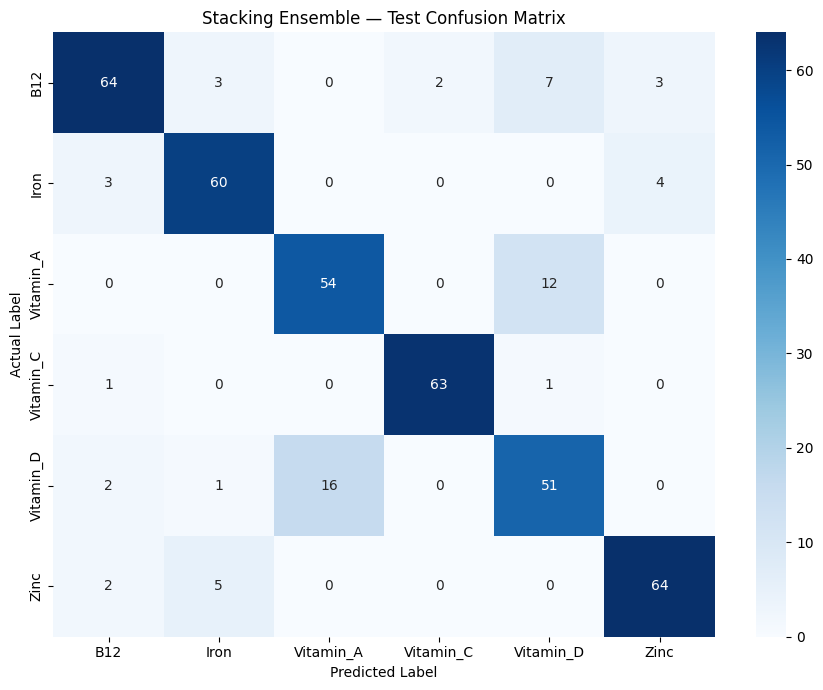


Saved test metrics and confusion matrix to:
/content/drive/MyDrive/Vitamin_deficiency_Dataset/model_results


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)
import pandas as pd
import numpy as np
import os
import time
import matplotlib.pyplot as plt
import seaborn as sns

# Predict on the held-out test set
start_time = time.time()
y_test_pred = stacking_model.predict(X_test_features)
inference_time = time.time() - start_time

# Calculate final test metrics
test_accuracy = accuracy_score(y_test_features, y_test_pred)
test_precision = precision_score(
    y_test_features, y_test_pred, average="macro", zero_division=0
)
test_recall = recall_score(
    y_test_features, y_test_pred, average="macro", zero_division=0
)
test_f1 = f1_score(
    y_test_features, y_test_pred, average="macro", zero_division=0
)

print("FINAL STACKING ENSEMBLE — TEST RESULTS")
print("-" * 45)
print(f"Test Accuracy:       {test_accuracy:.4f} ({test_accuracy * 100:.2f}%)")
print(f"Macro Precision:     {test_precision:.4f}")
print(f"Macro Recall:        {test_recall:.4f}")
print(f"Macro F1-score:      {test_f1:.4f}")
print(f"Inference Time:      {inference_time:.2f} seconds")
print(f"Test Images:         {len(y_test_features)}")

# Class-wise performance
class_names = test_loader.dataset.classes
print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_test_features,
    y_test_pred,
    labels=np.arange(len(class_names)),
    target_names=class_names,
    zero_division=0
))

# Save test metrics
os.makedirs(results_dir, exist_ok=True)

test_results = pd.DataFrame([{
    "Model": "Stacking Ensemble",
    "Test Accuracy": test_accuracy,
    "Macro Precision": test_precision,
    "Macro Recall": test_recall,
    "Macro F1": test_f1,
    "Inference Time (seconds)": inference_time,
    "Test Images": len(y_test_features)
}])

test_results.to_csv(
    os.path.join(results_dir, "stacking_test_results.csv"),
    index=False
)

# Plot and save confusion matrix
cm = confusion_matrix(
    y_test_features,
    y_test_pred,
    labels=np.arange(len(class_names))
)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Stacking Ensemble — Test Confusion Matrix")
plt.tight_layout()

plt.savefig(
    os.path.join(results_dir, "stacking_test_confusion_matrix.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("\nSaved test metrics and confusion matrix to:")
print(results_dir)

In [ ]:
print("Logistic Regression available:", "logistic_regression" in globals())
print("SVM available:", "svm_rbf" in globals())
print("Random Forest available:", "random_forest" in globals())
print("Test features available:", "X_test_features" in globals())
print("Test labels available:", "y_test_features" in globals())

Logistic Regression available: False
SVM available: False
Random Forest available: False
Test features available: True
Test labels available: True


In [ ]:
import os

model_files = {
    "Logistic Regression": "logistic_regression_deep_features.pkl",
    "SVM": "svm_rbf_deep_features.pkl",
    "Random Forest": "random_forest_deep_features.pkl"
}

for name, filename in model_files.items():
    path = os.path.join(results_dir, filename)
    print(f"{name}: {'Found' if os.path.exists(path) else 'Not found'}")

Logistic Regression: Found
SVM: Found
Random Forest: Found


In [ ]:
import os
import pickle
import time
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

model_files = {
    "Logistic Regression": "logistic_regression_deep_features.pkl",
    "SVM": "svm_rbf_deep_features.pkl",
    "Random Forest": "random_forest_deep_features.pkl"
}

individual_test_results = []

for model_name, filename in model_files.items():
    path = os.path.join(results_dir, filename)

    with open(path, "rb") as f:
        model = pickle.load(f)

    start_time = time.time()
    predictions = model.predict(X_test_features)
    inference_time = time.time() - start_time

    individual_test_results.append({
        "Model": model_name,
        "Test Accuracy": accuracy_score(y_test_features, predictions),
        "Macro Precision": precision_score(
            y_test_features, predictions, average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            y_test_features, predictions, average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            y_test_features, predictions, average="macro", zero_division=0
        ),
        "Inference Time (seconds)": inference_time
    })

individual_test_df = pd.DataFrame(individual_test_results)

print("INDIVIDUAL CLASSIFIERS — TEST RESULTS")
display(
    individual_test_df.style.format({
        "Test Accuracy": "{:.2%}",
        "Macro Precision": "{:.2%}",
        "Macro Recall": "{:.2%}",
        "Macro F1": "{:.2%}",
        "Inference Time (seconds)": "{:.2f}"
    })
)

individual_test_df.to_csv(
    os.path.join(results_dir, "individual_classifiers_test_results.csv"),
    index=False
)

print("\nSaved individual classifier test results.")

UnpicklingError: invalid load key, '\x03'.

In [ ]:
import os

for filename in [
    "logistic_regression_deep_features.pkl",
    "svm_rbf_deep_features.pkl",
    "random_forest_deep_features.pkl"
]:
    path = os.path.join(results_dir, filename)

    with open(path, "rb") as f:
        first_bytes = f.read(16)

    print(f"\n{filename}")
    print("File size:", os.path.getsize(path), "bytes")
    print("First 16 bytes:", repr(first_bytes))


logistic_regression_deep_features.pkl
File size: 314777 bytes
First 16 bytes: b'\x80\x04\x95\xf1\x01\x00\x00\x00\x00\x00\x00\x8c\x10skl'

svm_rbf_deep_features.pkl
File size: 98594981 bytes
First 16 bytes: b'\x80\x04\x95\xf1\x01\x00\x00\x00\x00\x00\x00\x8c\x10skl'

random_forest_deep_features.pkl
File size: 24486873 bytes
First 16 bytes: b'\x80\x04\x95\x95\x03\x00\x00\x00\x00\x00\x00\x8c\x18skl'


In [ ]:
import os
import joblib

model_files = {
    "Logistic Regression": "logistic_regression_deep_features.pkl",
    "SVM": "svm_rbf_deep_features.pkl",
    "Random Forest": "random_forest_deep_features.pkl"
}

loaded_models = {}

for name, filename in model_files.items():
    path = os.path.join(results_dir, filename)

    try:
        model = joblib.load(path)
        loaded_models[name] = model
        print(f"{name}: Loaded successfully ({type(model).__name__})")
    except Exception as e:
        print(f"{name}: Failed — {type(e).__name__}: {e}")

Logistic Regression: Loaded successfully (Pipeline)
SVM: Loaded successfully (Pipeline)
Random Forest: Loaded successfully (RandomForestClassifier)


In [ ]:
import os
import time
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

individual_test_results = []

for model_name, model in loaded_models.items():
    start_time = time.time()
    predictions = model.predict(X_test_features)
    inference_time = time.time() - start_time

    individual_test_results.append({
        "Model": model_name,
        "Test Accuracy": accuracy_score(y_test_features, predictions),
        "Macro Precision": precision_score(
            y_test_features, predictions, average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            y_test_features, predictions, average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            y_test_features, predictions, average="macro", zero_division=0
        ),
        "Inference Time (seconds)": inference_time
    })

individual_test_df = pd.DataFrame(individual_test_results)

display(
    individual_test_df.style.format({
        "Test Accuracy": "{:.2%}",
        "Macro Precision": "{:.2%}",
        "Macro Recall": "{:.2%}",
        "Macro F1": "{:.2%}",
        "Inference Time (seconds)": "{:.2f}"
    })
)

save_path = os.path.join(
    results_dir, "individual_classifiers_test_results.csv"
)
individual_test_df.to_csv(save_path, index=False)

print("Saved to:", save_path)

,Model,Test Accuracy,Macro Precision,Macro Recall,Macro F1,Inference Time (seconds)
0,Logistic Regression,85.41%,85.69%,85.61%,85.61%,0.02
1,SVM,84.93%,85.44%,85.01%,85.04%,7.19
2,Random Forest,79.43%,79.78%,79.67%,79.61%,0.09


Saved to: /content/drive/MyDrive/Vitamin_deficiency_Dataset/model_results/individual_classifiers_test_results.csv


In [ ]:
import os
import pandas as pd

results_dir = "/content/drive/MyDrive/Vitamin_deficiency_Dataset/model_results"

individual_path = os.path.join(
    results_dir, "individual_classifiers_test_results.csv"
)
stacking_path = os.path.join(
    results_dir, "stacking_test_results.csv"
)

individual_results = pd.read_csv(individual_path)
stacking_results = pd.read_csv(stacking_path)

print("INDIVIDUAL CLASSIFIER RESULTS")
display(individual_results)

print("\nSTACKING ENSEMBLE TEST RESULTS")
display(stacking_results)

print("\nAvailable columns:")
print("Individual:", individual_results.columns.tolist())
print("Stacking:", stacking_results.columns.tolist())

INDIVIDUAL CLASSIFIER RESULTS


,Model,Test Accuracy,Macro Precision,Macro Recall,Macro F1,Inference Time (seconds)
0,Logistic Regression,0.854067,0.856854,0.856077,0.856105,0.015532
1,SVM,0.849282,0.854416,0.850078,0.850409,7.191331
2,Random Forest,0.794258,0.797804,0.796717,0.796128,0.089983



STACKING ENSEMBLE TEST RESULTS


,Model,Test Accuracy,Macro Precision,Macro Recall,Macro F1,Inference Time (seconds),Test Images
0,Stacking Ensemble,0.851675,0.853139,0.85384,0.853033,11.089166,418



Available columns:
Individual: ['Model', 'Test Accuracy', 'Macro Precision', 'Macro Recall', 'Macro F1', 'Inference Time (seconds)']
Stacking: ['Model', 'Test Accuracy', 'Macro Precision', 'Macro Recall', 'Macro F1', 'Inference Time (seconds)', 'Test Images']


In [ ]:
import os
import pandas as pd

results_dir = "/content/drive/MyDrive/Vitamin_deficiency_Dataset/model_results"

individual = pd.read_csv(
    os.path.join(results_dir, "individual_classifiers_test_results.csv")
)

stacking = pd.read_csv(
    os.path.join(results_dir, "stacking_test_results.csv")
)

# Combine the three individual classifiers and stacking ensemble
final_results = pd.concat(
    [
        individual[
            [
                "Model",
                "Test Accuracy",
                "Macro Precision",
                "Macro Recall",
                "Macro F1",
                "Inference Time (seconds)"
            ]
        ],
        stacking[
            [
                "Model",
                "Test Accuracy",
                "Macro Precision",
                "Macro Recall",
                "Macro F1",
                "Inference Time (seconds)"
            ]
        ]
    ],
    ignore_index=True
)

# Convert metrics to percentages for readability
metric_columns = [
    "Test Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1"
]

final_table = final_results.copy()

for column in metric_columns:
    final_table[column] = (
        final_table[column] * 100
    ).round(2).astype(str) + "%"

final_table["Inference Time (seconds)"] = (
    final_table["Inference Time (seconds)"].round(3)
)

display(final_table)

output_path = os.path.join(
    results_dir, "final_test_comparison.csv"
)

final_results.to_csv(output_path, index=False)

print("Final comparison saved to:", output_path)

,Model,Test Accuracy,Macro Precision,Macro Recall,Macro F1,Inference Time (seconds)
0,Logistic Regression,85.41%,85.69%,85.61%,85.61%,0.016
1,SVM,84.93%,85.44%,85.01%,85.04%,7.191
2,Random Forest,79.43%,79.78%,79.67%,79.61%,0.090
3,Stacking Ensemble,85.17%,85.31%,85.38%,85.3%,11.089


Final comparison saved to: /content/drive/MyDrive/Vitamin_deficiency_Dataset/model_results/final_test_comparison.csv


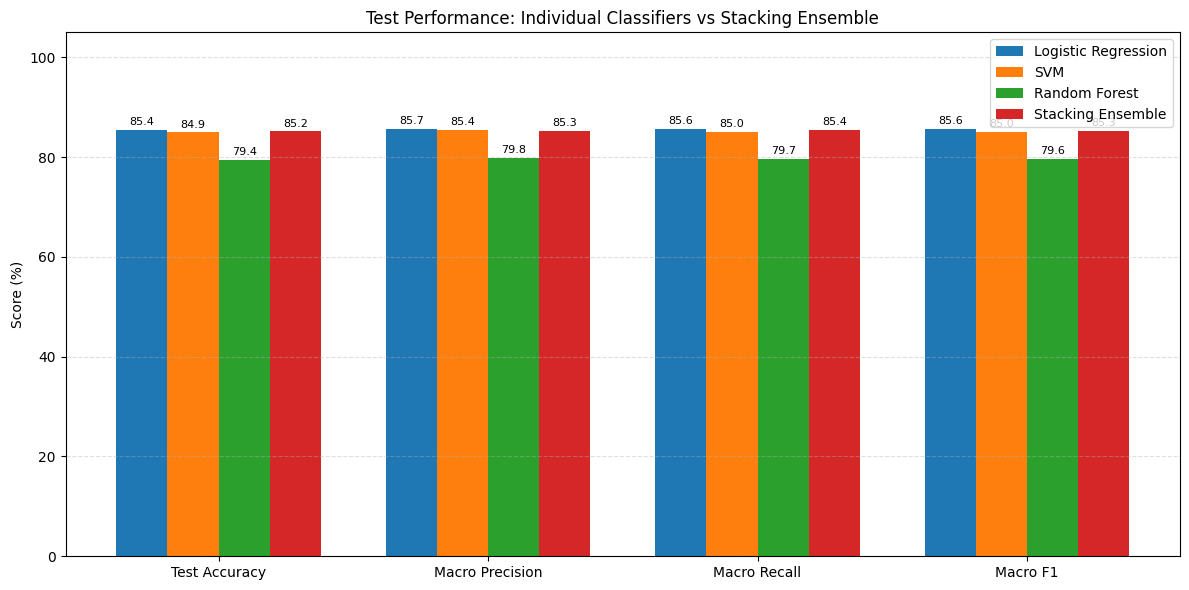

Comparison graph saved to: /content/drive/MyDrive/Vitamin_deficiency_Dataset/model_results/final_test_comparison.png


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import os

metrics = [
    "Test Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1"
]

x = np.arange(len(metrics))
width = 0.19

plt.figure(figsize=(12, 6))

for i, (_, row) in enumerate(final_results.iterrows()):
    values = [row[metric] * 100 for metric in metrics]

    positions = x + (i - 1.5) * width
    bars = plt.bar(
        positions,
        values,
        width,
        label=row["Model"]
    )

    plt.bar_label(
        bars,
        fmt="%.1f",
        fontsize=8,
        padding=2
    )

plt.xticks(x, metrics)
plt.ylabel("Score (%)")
plt.title("Test Performance: Individual Classifiers vs Stacking Ensemble")
plt.ylim(0, 105)
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()

graph_path = os.path.join(
    results_dir, "final_test_comparison.png"
)

plt.savefig(graph_path, dpi=300, bbox_inches="tight")
plt.show()

print("Comparison graph saved to:", graph_path)

In [ ]:
import os
import pandas as pd

results_dir = "/content/drive/MyDrive/Vitamin_deficiency_Dataset/model_results"

files_to_check = [
    "feature_extraction_comparison.csv",
    "individual_classifier_results.csv",
    "stacking_validation_results.csv",
    "stacking_test_results.csv",
    "individual_classifiers_test_results.csv",
    "final_test_comparison.csv",
    "final_test_comparison.png"
]

for filename in files_to_check:
    path = os.path.join(results_dir, filename)
    print(f"{filename}: {'EXISTS' if os.path.exists(path) else 'MISSING'}")

feature_path = os.path.join(
    results_dir, "feature_extraction_comparison.csv"
)

if os.path.exists(feature_path):
    print("\nFEATURE EXTRACTION COMPARISON")
    feature_results = pd.read_csv(feature_path)
    display(feature_results)

feature_extraction_comparison.csv: EXISTS
individual_classifier_results.csv: EXISTS
stacking_validation_results.csv: EXISTS
stacking_test_results.csv: EXISTS
individual_classifiers_test_results.csv: EXISTS
final_test_comparison.csv: EXISTS
final_test_comparison.png: EXISTS

FEATURE EXTRACTION COMPARISON


,Feature_Set,Feature_Dimensions,Accuracy,Macro_F1,Training_Time_Seconds
0,GoogLeNet features,1024,0.182039,0.181246,10.715930
1,ResNet-50 features,2048,0.162621,0.160409,6.139650
2,MobileNetV2 features,1280,0.201456,0.199172,6.459830
3,Hybrid combined features,4352,0.856796,0.856211,5.102059


In [ ]:
# Step 1: Inspect the current feature extraction setup

print("DATASET INFORMATION")
print("Train images:", len(train_loader.dataset))
print("Validation images:", len(val_loader.dataset))
print("Test images:", len(test_loader.dataset))

print("\nCLASS NAMES")
print("Train:", train_loader.dataset.classes)
print("Validation:", val_loader.dataset.classes)
print("Test:", test_loader.dataset.classes)

print("\nTRAIN TRANSFORM")
print(train_loader.dataset.transform)

print("\nVALIDATION TRANSFORM")
print(val_loader.dataset.transform)

print("\nTEST TRANSFORM")
print(test_loader.dataset.transform)

print("\nCNN MODELS")
for name in ["googlenet", "resnet", "mobilenet"]:
    if name in globals():
        print(name, "exists:", type(globals()[name]).__name__)
    else:
        print(name, "is not currently available")

print("\nFEATURE ARRAYS")
for name in [
    "X_train_features", "X_val_features",
    "G_train", "R_train", "M_train",
    "X_test_features", "y_train_features"
]:
    if name in globals():
        value = globals()[name]
        print(name, "shape:", getattr(value, "shape", "shape unavailable"))
    else:
        print(name, "is not currently available")

DATASET INFORMATION
Train images: 3287
Validation images: 412
Test images: 418

CLASS NAMES
Train: ['B12', 'Iron', 'Vitamin_A', 'Vitamin_C', 'Vitamin_D', 'Zinc']
Validation: ['B12', 'Iron', 'Vitamin_A', 'Vitamin_C', 'Vitamin_D', 'Zinc']
Test: ['B12', 'Iron', 'Vitamin_A', 'Vitamin_C', 'Vitamin_D', 'Zinc']

TRAIN TRANSFORM
Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    RandomHorizontalFlip(p=0.5)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

VALIDATION TRANSFORM
Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

TEST TRANSFORM
Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

CNN MODELS
googlenet exists: GoogLeNet
resnet exists: ResNet
mobilenet e

In [ ]:
import torch
import torch.nn as nn

models_to_check = {
    "GoogLeNet": googlenet,
    "ResNet-50": resnet,
    "MobileNetV2": mobilenet
}

for name, model in models_to_check.items():
    print(f"\n{name}")
    print("-" * 40)

    model.eval()

    if name == "GoogLeNet":
        print("FC layer:", model.fc)
    elif name == "ResNet-50":
        print("FC layer:", model.fc)
    else:
        print("Classifier layer:", model.classifier)

    print("Model device:", next(model.parameters()).device)
    print("Model training mode:", model.training)

print("\nFeature array dimensions:")
print("GoogLeNet train:", G_train.shape)
print("ResNet-50 train:", R_train.shape)
print("MobileNetV2 train:", M_train.shape)
print("Combined train:", X_train_features.shape)

print("\nFeature labels:")
print("Training labels:", y_train_features.shape)
print("Validation labels:", y_val.shape)





GoogLeNet
----------------------------------------
FC layer: Identity()
Model device: cuda:0
Model training mode: False

ResNet-50
----------------------------------------
FC layer: Identity()
Model device: cuda:0
Model training mode: False

MobileNetV2
----------------------------------------
Classifier layer: Identity()
Model device: cuda:0
Model training mode: False

Feature array dimensions:
GoogLeNet train: (3287, 1024)
ResNet-50 train: (3287, 2048)
MobileNetV2 train: (3287, 1280)
Combined train: (3287, 4352)

Feature labels:
Training labels: (3287,)
Validation labels: (412,)


In [ ]:
import numpy as np
import torch
from tqdm.auto import tqdm

# Save the original training transform
original_train_transform = train_loader.dataset.transform

# Use deterministic preprocessing, matching validation and test
train_loader.dataset.transform = val_loader.dataset.transform

googlenet.eval()
resnet.eval()
mobilenet.eval()

G_train_new = []
R_train_new = []
M_train_new = []
y_train_new = []

device = next(googlenet.parameters()).device

with torch.no_grad():
    for images, labels in tqdm(train_loader, desc="Extracting consistent features"):
        images = images.to(device)

        # Extract features from each CNN
        g_features = googlenet(images)
        r_features = resnet(images)
        m_features = mobilenet(images)

        G_train_new.append(g_features.cpu().numpy())
        R_train_new.append(r_features.cpu().numpy())
        M_train_new.append(m_features.cpu().numpy())
        y_train_new.append(labels.numpy())

# Restore the original training transform
train_loader.dataset.transform = original_train_transform

# Combine batches
G_train_new = np.concatenate(G_train_new, axis=0)
R_train_new = np.concatenate(R_train_new, axis=0)
M_train_new = np.concatenate(M_train_new, axis=0)
y_train_new = np.concatenate(y_train_new, axis=0)

# Combine all three feature extraction techniques
X_train_features_new = np.concatenate(
    [G_train_new, R_train_new, M_train_new],
    axis=1
)
y_train_features_new = y_train_new.copy()

print("\nNEW FEATURE SHAPES")
print("GoogLeNet:", G_train_new.shape)
print("ResNet-50:", R_train_new.shape)
print("MobileNetV2:", M_train_new.shape)
print("Combined:", X_train_features_new.shape)
print("Labels:", y_train_features_new.shape)

print("\nCHECKS")
print("All features finite:",
      np.isfinite(X_train_features_new).all())
print("Labels match previous training order:",
      np.array_equal(y_train_features_new, y_train_features))
print("Transform restored:",
      train_loader.dataset.transform == original_train_transform)

Extracting consistent features:   0%|          | 0/103 [00:00<?, ?it/s]


NEW FEATURE SHAPES
GoogLeNet: (3287, 1024)
ResNet-50: (3287, 2048)
MobileNetV2: (3287, 1280)
Combined: (3287, 4352)
Labels: (3287,)

CHECKS
All features finite: True
Labels match previous training order: False
Transform restored: True


In [ ]:
print("NEW LABELS — first 30")
print(y_train_new[:30])

print("\nOLD LABELS — first 30")
print(y_train_features[:30])

print("\nNEW LABEL COUNTS")
import numpy as np
print(np.unique(y_train_new, return_counts=True))

print("\nOLD LABEL COUNTS")
print(np.unique(y_train_features, return_counts=True))

print("\nTRAIN LOADER SETTINGS")
print("Shuffle:", train_loader.sampler)
print("Batch size:", train_loader.batch_size)
print("Drop last:", train_loader.drop_last)

print("\nDATASET SETTINGS")
print("Dataset type:", type(train_loader.dataset).__name__)
print("Dataset length:", len(train_loader.dataset))

NEW LABELS — first 30
[5 5 5 2 2 1 4 2 4 0 3 1 1 3 2 2 5 1 2 2 5 0 5 5 2 0 5 0 1 5]

OLD LABELS — first 30
[3 5 5 1 2 2 5 2 0 0 3 4 0 4 3 1 5 3 4 3 0 0 0 3 1 3 2 3 3 5]

NEW LABEL COUNTS
(array([0, 1, 2, 3, 4, 5]), array([622, 530, 518, 509, 550, 558]))

OLD LABEL COUNTS
(array([0, 1, 2, 3, 4, 5]), array([622, 530, 518, 509, 550, 558]))

TRAIN LOADER SETTINGS
Shuffle: <torch.utils.data.sampler.RandomSampler object at 0x78fb0ece8410>
Batch size: 32
Drop last: False

DATASET SETTINGS
Dataset type: ImageFolder
Dataset length: 3287


In [ ]:
from torch.utils.data import DataLoader

# Save the current training transform
original_train_transform = train_loader.dataset.transform

# Use deterministic preprocessing, like validation and test
train_loader.dataset.transform = val_loader.dataset.transform

# Create a loader that preserves dataset order
train_loader_fixed = DataLoader(
    train_loader.dataset,
    batch_size=32,
    shuffle=False,
    num_workers=train_loader.num_workers,
    pin_memory=True
)

print("Training samples:", len(train_loader_fixed.dataset))
print("Shuffle:", isinstance(train_loader_fixed.sampler, torch.utils.data.RandomSampler))
print("First 30 labels:")

labels_check = []
for images, labels in train_loader_fixed:
    labels_check.extend(labels.numpy().tolist())
    if len(labels_check) >= 30:
        break

print(labels_check[:30])

# Restore the original training transform
train_loader.dataset.transform = original_train_transform

Training samples: 3287
Shuffle: False
First 30 labels:
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


In [ ]:
import torch
import numpy as np
from tqdm.auto import tqdm

# Use deterministic preprocessing
original_train_transform = train_loader_fixed.dataset.transform
train_loader_fixed.dataset.transform = val_loader.dataset.transform

googlenet.eval()
resnet.eval()
mobilenet.eval()

G_train_fixed = []
R_train_fixed = []
M_train_fixed = []
y_train_fixed = []

device = next(googlenet.parameters()).device

with torch.no_grad():
    for images, labels in tqdm(train_loader_fixed, desc="Extracting fixed-order features"):
        images = images.to(device)

        g = googlenet(images)
        r = resnet(images)
        m = mobilenet(images)

        G_train_fixed.append(g.cpu().numpy())
        R_train_fixed.append(r.cpu().numpy())
        M_train_fixed.append(m.cpu().numpy())
        y_train_fixed.extend(labels.numpy().tolist())

# Restore original preprocessing
train_loader_fixed.dataset.transform = original_train_transform

# Combine batches
G_train_fixed = np.concatenate(G_train_fixed, axis=0)
R_train_fixed = np.concatenate(R_train_fixed, axis=0)
M_train_fixed = np.concatenate(M_train_fixed, axis=0)
y_train_fixed = np.array(y_train_fixed)

X_train_fixed = np.concatenate(
    [G_train_fixed, R_train_fixed, M_train_fixed], axis=1
)

print("\nFeature extraction complete!")
print("GoogLeNet:", G_train_fixed.shape)
print("ResNet-50:", R_train_fixed.shape)
print("MobileNetV2:", M_train_fixed.shape)
print("Combined:", X_train_fixed.shape)
print("Labels:", y_train_fixed.shape)
print("Class counts:", np.unique(y_train_fixed, return_counts=True))
print("All features finite:", np.isfinite(X_train_fixed).all())

Extracting fixed-order features:   0%|          | 0/103 [00:00<?, ?it/s]


Feature extraction complete!
GoogLeNet: (3287, 1024)
ResNet-50: (3287, 2048)
MobileNetV2: (3287, 1280)
Combined: (3287, 4352)
Labels: (3287,)
Class counts: (array([0, 1, 2, 3, 4, 5]), array([622, 530, 518, 509, 550, 558]))
All features finite: True


In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd
import time

# Use validation labels and features
feature_sets = {
    "GoogLeNet": (G_train_fixed, G_train_fixed.shape[1]),
    "ResNet-50": (R_train_fixed, R_train_fixed.shape[1]),
    "MobileNetV2": (M_train_fixed, M_train_fixed.shape[1])
}

# Validation features must be in the same order:
# GoogLeNet -> ResNet-50 -> MobileNetV2
G_val = X_val_features[:, :1024]
R_val = X_val_features[:, 1024:3072]
M_val = X_val_features[:, 3072:]

validation_sets = {
    "GoogLeNet": (G_val, y_val),
    "ResNet-50": (R_val, y_val),
    "MobileNetV2": (M_val, y_val)
}

results = []

for name, (X_train_part, _) in feature_sets.items():
    X_valid_part, y_valid = validation_sets[name]

    model = make_pipeline(
        StandardScaler(),
        LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        )
    )

    start = time.time()
    model.fit(X_train_part, y_train_fixed)
    train_time = time.time() - start

    predictions = model.predict(X_valid_part)

    results.append({
        "Feature Extractor": name,
        "Feature Count": X_train_part.shape[1],
        "Accuracy (%)": round(accuracy_score(y_valid, predictions) * 100, 2),
        "Precision (%)": round(precision_score(y_valid, predictions, average="macro", zero_division=0) * 100, 2),
        "Recall (%)": round(recall_score(y_valid, predictions, average="macro", zero_division=0) * 100, 2),
        "F1-Score (%)": round(f1_score(y_valid, predictions, average="macro", zero_division=0) * 100, 2),
        "Training Time (s)": round(train_time, 2)
    })

feature_comparison_df = pd.DataFrame(results)
display(feature_comparison_df)

,Feature Extractor,Feature Count,Accuracy (%),Precision (%),Recall (%),F1-Score (%),Training Time (s)
0,GoogLeNet,1024,73.79,74.48,73.87,73.94,6.09
1,ResNet-50,2048,81.55,81.62,81.66,81.52,5.09
2,MobileNetV2,1280,79.13,79.21,79.46,79.16,3.90


In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import time
import pandas as pd

hybrid_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    )
)

start = time.time()
hybrid_model.fit(X_train_fixed, y_train_fixed)
hybrid_train_time = time.time() - start

hybrid_predictions = hybrid_model.predict(X_val_features)

hybrid_result = {
    "Feature Extractor": "Hybrid (GoogLeNet + ResNet-50 + MobileNetV2)",
    "Feature Count": X_train_fixed.shape[1],
    "Accuracy (%)": round(accuracy_score(y_val, hybrid_predictions) * 100, 2),
    "Precision (%)": round(precision_score(y_val, hybrid_predictions, average="macro", zero_division=0) * 100, 2),
    "Recall (%)": round(recall_score(y_val, hybrid_predictions, average="macro", zero_division=0) * 100, 2),
    "F1-Score (%)": round(f1_score(y_val, hybrid_predictions, average="macro", zero_division=0) * 100, 2),
    "Training Time (s)": round(hybrid_train_time, 2)
}

print(pd.DataFrame([hybrid_result]).to_string(index=False))

                           Feature Extractor  Feature Count  Accuracy (%)  Precision (%)  Recall (%)  F1-Score (%)  Training Time (s)
Hybrid (GoogLeNet + ResNet-50 + MobileNetV2)           4352         85.19          85.19       85.23          85.1               7.67


In [ ]:
from sklearn.ensemble import StackingClassifier, RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import time
import pandas as pd

base_models = [
    ("logistic_regression", make_pipeline(
        StandardScaler(),
        LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        )
    )),
    ("svm", make_pipeline(
        StandardScaler(),
        SVC(
            kernel="rbf",
            C=1.0,
            probability=True,
            class_weight="balanced",
            random_state=42
        )
    )),
    ("random_forest", RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
]

stacking_model_fixed = StackingClassifier(
    estimators=base_models,
    final_estimator=LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ),
    stack_method="predict_proba",
    cv=3,
    n_jobs=1
)

start = time.time()
stacking_model_fixed.fit(X_train_fixed, y_train_fixed)
stack_train_time = time.time() - start

stack_val_predictions = stacking_model_fixed.predict(X_val_features)

stack_result = {
    "Model": "Stacking Ensemble",
    "Accuracy (%)": round(accuracy_score(y_val, stack_val_predictions) * 100, 2),
    "Precision (%)": round(precision_score(y_val, stack_val_predictions, average="macro", zero_division=0) * 100, 2),
    "Recall (%)": round(recall_score(y_val, stack_val_predictions, average="macro", zero_division=0) * 100, 2),
    "F1-Score (%)": round(f1_score(y_val, stack_val_predictions, average="macro", zero_division=0) * 100, 2),
    "Training Time (s)": round(stack_train_time, 2)
}

print(pd.DataFrame([stack_result]).to_string(index=False))

            Model  Accuracy (%)  Precision (%)  Recall (%)  F1-Score (%)  Training Time (s)
Stacking Ensemble         83.25          84.24       83.39         83.27             854.66


In [ ]:
import os
import pandas as pd

results_dir = "/content/drive/MyDrive/Vitamin_deficiency_Dataset/model_results"
os.makedirs(results_dir, exist_ok=True)

final_validation_results = pd.DataFrame([
    {
        "Model": "GoogLeNet + Logistic Regression",
        "Accuracy (%)": 73.79,
        "Precision (%)": 74.48,
        "Recall (%)": 73.87,
        "F1-Score (%)": 73.94
    },
    {
        "Model": "ResNet-50 + Logistic Regression",
        "Accuracy (%)": 81.55,
        "Precision (%)": 81.62,
        "Recall (%)": 81.66,
        "F1-Score (%)": 81.52
    },
    {
        "Model": "MobileNetV2 + Logistic Regression",
        "Accuracy (%)": 79.13,
        "Precision (%)": 79.21,
        "Recall (%)": 79.46,
        "F1-Score (%)": 79.16
    },
    {
        "Model": "Hybrid + Logistic Regression",
        "Accuracy (%)": 85.19,
        "Precision (%)": 85.19,
        "Recall (%)": 85.23,
        "F1-Score (%)": 85.10
    },
    {
        "Model": "Stacking Ensemble",
        "Accuracy (%)": 83.25,
        "Precision (%)": 84.24,
        "Recall (%)": 83.39,
        "F1-Score (%)": 83.27
    }
])

output_path = os.path.join(
    results_dir, "corrected_validation_comparison.csv"
)
final_validation_results.to_csv(output_path, index=False)

display(final_validation_results)
print("Saved to:", output_path)

,Model,Accuracy (%),Precision (%),Recall (%),F1-Score (%)
0,GoogLeNet + Logistic Regression,73.79,74.48,73.87,73.94
1,ResNet-50 + Logistic Regression,81.55,81.62,81.66,81.52
2,MobileNetV2 + Logistic Regression,79.13,79.21,79.46,79.16
3,Hybrid + Logistic Regression,85.19,85.19,85.23,85.10
4,Stacking Ensemble,83.25,84.24,83.39,83.27


Saved to: /content/drive/MyDrive/Vitamin_deficiency_Dataset/model_results/corrected_validation_comparison.csv


In [ ]:
print("Test features available:", "X_test_features" in globals())
print("Test labels available:", "y_test" in globals())

if "X_test_features" in globals():
    print("Test feature shape:", X_test_features.shape)

if "y_test" in globals():
    print("Test label shape:", y_test.shape)
elif "y_test_features" in globals():
    print("Alternative test labels available:", y_test_features.shape)

Test features available: True
Test labels available: False
Test feature shape: (418, 4352)
Alternative test labels available: (418,)


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Use the available test labels
y_test_final = y_test_features

# Evaluate the corrected hybrid Logistic Regression model
hybrid_pred = hybrid_model.predict(X_test_features)

# Evaluate the corrected stacking model
stacking_pred = stacking_model_fixed.predict(X_test_features)

print("FINAL TEST RESULTS")
print("-" * 50)

for name, predictions in [
    ("Hybrid Logistic Regression", hybrid_pred),
    ("Stacking Ensemble", stacking_pred)
]:
    print(f"\n{name}")
    print(f"Accuracy:  {accuracy_score(y_test_final, predictions) * 100:.2f}%")
    print(f"Precision: {precision_score(y_test_final, predictions, average='macro', zero_division=0) * 100:.2f}%")
    print(f"Recall:    {recall_score(y_test_final, predictions, average='macro', zero_division=0) * 100:.2f}%")
    print(f"F1-score:  {f1_score(y_test_final, predictions, average='macro', zero_division=0) * 100:.2f}%")

FINAL TEST RESULTS
--------------------------------------------------

Hybrid Logistic Regression
Accuracy:  83.01%
Precision: 83.14%
Recall:    83.31%
F1-score:  83.14%

Stacking Ensemble
Accuracy:  83.97%
Precision: 84.57%
Recall:    84.28%
F1-score:  84.19%


In [ ]:
print("Test labels distribution:")
print(np.bincount(y_test_features))

print("\nTest dataset labels distribution:")
print(np.bincount(
    [label for _, label in test_loader.dataset.samples]
))

Test labels distribution:
[79 67 66 65 70 71]

Test dataset labels distribution:
[79 67 66 65 70 71]


In [ ]:
import time
import pandas as pd
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score
)

models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=2000, random_state=42)
    ),
    "SVM": make_pipeline(
        StandardScaler(),
        SVC(kernel="rbf", random_state=42)
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, random_state=42, n_jobs=-1
    )
}

results = []

for name, model in models.items():
    start = time.time()
    model.fit(X_train_fixed, y_train_fixed)
    predictions = model.predict(X_test_features)

    results.append({
        "Model": name,
        "Accuracy (%)": round(accuracy_score(y_test_features, predictions) * 100, 2),
        "Macro Precision (%)": round(precision_score(y_test_features, predictions, average="macro", zero_division=0) * 100, 2),
        "Macro Recall (%)": round(recall_score(y_test_features, predictions, average="macro", zero_division=0) * 100, 2),
        "Macro F1 (%)": round(f1_score(y_test_features, predictions, average="macro", zero_division=0) * 100, 2),
        "Training Time (s)": round(time.time() - start, 2)
    })

# Add the previously evaluated corrected models
for name, predictions in [
    ("Hybrid Logistic Regression", hybrid_model.predict(X_test_features)),
    ("Stacking Ensemble", stacking_model_fixed.predict(X_test_features))
]:
    results.append({
        "Model": name,
        "Accuracy (%)": round(accuracy_score(y_test_features, predictions) * 100, 2),
        "Macro Precision (%)": round(precision_score(y_test_features, predictions, average="macro", zero_division=0) * 100, 2),
        "Macro Recall (%)": round(recall_score(y_test_features, predictions, average="macro", zero_division=0) * 100, 2),
        "Macro F1 (%)": round(f1_score(y_test_features, predictions, average="macro", zero_division=0) * 100, 2),
        "Training Time (s)": None
    })

final_comparison = pd.DataFrame(results).sort_values(
    "Accuracy (%)", ascending=False
).reset_index(drop=True)

display(final_comparison)

,Model,Accuracy (%),Macro Precision (%),Macro Recall (%),Macro F1 (%),Training Time (s)
0,SVM,86.60,87.18,86.63,86.75,65.85
1,Stacking Ensemble,83.97,84.57,84.28,84.19,NaN
2,Logistic Regression,83.01,83.14,83.31,83.14,9.25
3,Hybrid Logistic Regression,83.01,83.14,83.31,83.14,NaN
4,Random Forest,78.95,79.29,79.19,79.05,33.42


In [ ]:
print("Stacking model details:")
print(stacking_model_fixed)

print("\nHybrid model details:")
print(hybrid_model)

Stacking model details:
StackingClassifier(cv=3,
                   estimators=[('logistic_regression',
                                Pipeline(steps=[('standardscaler',
                                                 StandardScaler()),
                                                ('logisticregression',
                                                 LogisticRegression(class_weight='balanced',
                                                                    max_iter=1000,
                                                                    random_state=42))])),
                               ('svm',
                                Pipeline(steps=[('standardscaler',
                                                 StandardScaler()),
                                                ('svc',
                                                 SVC(class_weight='balanced',
                                                     probability=True,
                                             

In [ ]:
from sklearn.ensemble import StackingClassifier, RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.base import clone
import time

stacking_rf_meta = StackingClassifier(
    estimators=[
        ("logistic_regression", clone(stacking_model_fixed.estimators[0][1])),
        ("svm", clone(stacking_model_fixed.estimators[1][1])),
        ("random_forest", clone(stacking_model_fixed.estimators[2][1]))
    ],
    final_estimator=RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),
    cv=3,
    stack_method="predict_proba",
    n_jobs=1
)

start = time.time()
stacking_rf_meta.fit(X_train_fixed, y_train_fixed)
pred = stacking_rf_meta.predict(X_test_features)

print("Stacking with Random Forest meta-classifier")
print(f"Accuracy:  {accuracy_score(y_test_features, pred)*100:.2f}%")
print(f"Precision: {precision_score(y_test_features, pred, average='macro', zero_division=0)*100:.2f}%")
print(f"Recall:    {recall_score(y_test_features, pred, average='macro', zero_division=0)*100:.2f}%")
print(f"F1-score:  {f1_score(y_test_features, pred, average='macro', zero_division=0)*100:.2f}%")
print(f"Training time: {time.time()-start:.2f} seconds")

Stacking with Random Forest meta-classifier
Accuracy:  83.97%
Precision: 84.40%
Recall:    84.33%
F1-score:  84.31%
Training time: 971.92 seconds


In [ ]:

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd
import time

feature_sets = {
    "GoogLeNet": (G_train_fixed, X_test_features[:, :1024]),
    "ResNet-50": (R_train_fixed, X_test_features[:, 1024:3072]),
    "MobileNetV2": (M_train_fixed, X_test_features[:, 3072:])
}

results = []

for name, (X_train, X_test) in feature_sets.items():
    start = time.time()

    model = make_pipeline(
        StandardScaler(),
        LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=42
        )
    )

    model.fit(X_train, y_train_fixed)
    predictions = model.predict(X_test)

    results.append({
        "Feature Extractor": name,
        "Accuracy (%)": round(accuracy_score(
            y_test_features, predictions
        ) * 100, 2),
        "Precision (%)": round(precision_score(
            y_test_features, predictions,
            average="macro", zero_division=0
        ) * 100, 2),
        "Recall (%)": round(recall_score(
            y_test_features, predictions,
            average="macro", zero_division=0
        ) * 100, 2),
        "F1 Score (%)": round(f1_score(
            y_test_features, predictions,
            average="macro", zero_division=0
        ) * 100, 2),
        "Training Time (s)": round(time.time() - start, 2)
    })

comparison_df = pd.DataFrame(results)
display(comparison_df)


,Feature Extractor,Accuracy (%),Precision (%),Recall (%),F1 Score (%),Training Time (s)
0,GoogLeNet,73.68,73.64,74.02,73.69,9.96
1,ResNet-50,81.34,81.62,81.61,81.56,7.60
2,MobileNetV2,82.06,82.21,82.34,82.19,6.51


In [ ]:

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import time
import pandas as pd

lr = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    )
)

svm = make_pipeline(
    StandardScaler(),
    SVC(
        C=1.0,
        kernel="rbf",
        probability=True,
        class_weight="balanced",
        random_state=42
    )
)

rf = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

voting_model = VotingClassifier(
    estimators=[
        ("lr", lr),
        ("svm", svm),
        ("rf", rf)
    ],
    voting="soft",
    weights=[1, 2, 1],
    n_jobs=-1
)

start = time.time()

voting_model.fit(X_train_fixed, y_train_fixed)
predictions = voting_model.predict(X_test_features)

voting_results = pd.DataFrame([{
    "Model": "Soft Voting Ensemble",
    "Accuracy (%)": round(
        accuracy_score(y_test_features, predictions) * 100, 2
    ),
    "Precision (%)": round(
        precision_score(
            y_test_features, predictions,
            average="macro", zero_division=0
        ) * 100, 2
    ),
    "Recall (%)": round(
        recall_score(
            y_test_features, predictions,
            average="macro", zero_division=0
        ) * 100, 2
    ),
    "F1 Score (%)": round(
        f1_score(
            y_test_features, predictions,
            average="macro", zero_division=0
        ) * 100, 2
    ),
    "Training Time (s)": round(time.time() - start, 2)
}])

display(voting_results)


,Model,Accuracy (%),Precision (%),Recall (%),F1 Score (%),Training Time (s)
0,Soft Voting Ensemble,84.93,85.1,85.03,85.01,275.97


In [ ]:
import pandas as pd
from pathlib import Path

results = [
    ["GoogLeNet + LR", 73.68, 73.64, 74.02, 73.69],
    ["ResNet-50 + LR", 81.34, 81.62, 81.61, 81.56],
    ["MobileNetV2 + LR", 82.06, 82.21, 82.34, 82.19],
    ["Combined Features + LR", 83.01, 83.14, 83.31, 83.14],
    ["Combined Features + SVM", 86.60, 87.18, 86.63, 86.75],
    ["Stacking Ensemble (LR Meta)", 83.97, 84.57, 84.28, 84.19],
    ["Stacking Ensemble (RF Meta)", 83.97, 84.40, 84.33, 84.31],
    ["Soft Voting Ensemble", 84.93, 85.10, 85.03, 85.01],
]

columns = [
    "Model",
    "Accuracy (%)",
    "Precision (%)",
    "Recall (%)",
    "F1 Score (%)"
]

comparison_df = pd.DataFrame(results, columns=columns)

display(comparison_df)

save_path = Path(
    "/content/drive/MyDrive/Vitamin_deficiency_Dataset/"
    "model_results/consolidated_test_comparison.csv"
)

save_path.parent.mkdir(parents=True, exist_ok=True)
comparison_df.to_csv(save_path, index=False)

print("Saved to:", save_path)

,Model,Accuracy (%),Precision (%),Recall (%),F1 Score (%)
0,GoogLeNet + LR,73.68,73.64,74.02,73.69
1,ResNet-50 + LR,81.34,81.62,81.61,81.56
2,MobileNetV2 + LR,82.06,82.21,82.34,82.19
3,Combined Features + LR,83.01,83.14,83.31,83.14
4,Combined Features + SVM,86.60,87.18,86.63,86.75
5,Stacking Ensemble (LR Meta),83.97,84.57,84.28,84.19
6,Stacking Ensemble (RF Meta),83.97,84.40,84.33,84.31
7,Soft Voting Ensemble,84.93,85.10,85.03,85.01


Saved to: /content/drive/MyDrive/Vitamin_deficiency_Dataset/model_results/consolidated_test_comparison.csv


In [ ]:
import torch
import torchvision
import numpy as np

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

required_variables = [
    "X_train_fixed",
    "y_train_fixed",
    "X_val_features",
    "y_val",
    "X_test_features",
    "y_test_features",
    "G_train_fixed",
    "R_train_fixed",
    "M_train_fixed"
]

for name in required_variables:
    if name in globals():
        print(name, "->", np.shape(globals()[name]))
    else:
        print(name, "-> NOT FOUND")

PyTorch: 2.11.0+cpu
Torchvision: 0.26.0+cpu
GPU available: False
X_train_fixed -> NOT FOUND
y_train_fixed -> NOT FOUND
X_val_features -> NOT FOUND
y_val -> NOT FOUND
X_test_features -> NOT FOUND
y_test_features -> NOT FOUND
G_train_fixed -> NOT FOUND
R_train_fixed -> NOT FOUND
M_train_fixed -> NOT FOUND


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os

path = "/content/drive/MyDrive/Vitamin_deficiency_Dataset/model_results"

if os.path.exists(path):
    print("Saved results found:")
    for file in os.listdir(path):
        print(file)
else:
    print("Model results folder not found at:", path)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Saved results found:
googlenet_best.pth
googlenet_history.csv
resnet50_best.pth
resnet50_history.csv
mobilenetv2_best.pth
mobilenetv2_history.csv
ensemble_googlenet_resnet50.csv
ensemble_resnet50_mobilenetv2.csv
ensemble_googlenet_mobilenetv2.csv
ensemble_all_three.csv
seven_model_comparison.csv
adaboost_deep_features.pkl
adaboost_validation_results.csv
xgboost_deep_features.pkl
xgboost_validation_results.csv
lightgbm_deep_features.pkl
lightgbm_validation_results.csv
catboost_deep_features.pkl
catboost_validation_results.csv
logistic_regression_deep_features.pkl
svm_rbf_deep_features.pkl
random_forest_deep_features.pkl
individual_classifier_results.csv
feature_extraction_comparison.csv
stacking_ensemble.pkl
stacking_validation_results.csv
stacking_test_results.csv
stacking_test_confusion_matrix.png
individual_classifiers_test_results.csv
final_test_comparison

In [ ]:
import os

base_path = "/content/drive/MyDrive/Vitamin_deficiency_Dataset"

print("Checking saved feature and model files:\n")

for root, dirs, files in os.walk(base_path):
    dirs[:] = [d for d in dirs if d not in ["extracted"]]

    for file in files:
        if file.endswith((
            ".npy", ".npz", ".pkl", ".pt", ".pth"
        )):
            print(os.path.relpath(os.path.join(root, file), base_path))

In [ ]:
import os
import torch
import torchvision

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

dataset_path = (
    "/content/drive/MyDrive/"
    "Vitamin_deficiency_Dataset/extracted/"
    "Vitamin_Deficiency_Dataset_Preprocessed"
)

results_path = (
    "/content/drive/MyDrive/"
    "Vitamin_deficiency_Dataset/model_results"
)

print("\nDataset folder exists:", os.path.exists(dataset_path))
print("Previous results folder exists:", os.path.exists(results_path))

if os.path.exists(dataset_path):
    print("\nDataset class folders:")
    print(sorted([
        name for name in os.listdir(dataset_path)
        if os.path.isdir(os.path.join(dataset_path, name))
    ]))

if os.path.exists(results_path):
    print("\nSaved result files:")
    print(sorted(os.listdir(results_path)))

PyTorch: 2.11.0+cu130
Torchvision: 0.26.0+cu130
GPU available: True
GPU: Tesla T4

Dataset folder exists: True
Previous results folder exists: True

Dataset class folders:
['Test', 'Train', 'Validation']

Saved result files:
['adaboost_deep_features.pkl', 'adaboost_validation_results.csv', 'catboost_deep_features.pkl', 'catboost_validation_results.csv', 'cnn_combination_comparison.csv', 'consolidated_test_comparison.csv', 'corrected_validation_comparison.csv', 'ensemble_all_three.csv', 'ensemble_googlenet_mobilenetv2.csv', 'ensemble_googlenet_resnet50.csv', 'ensemble_resnet50_mobilenetv2.csv', 'feature_extraction_comparison.csv', 'final_test_comparison.csv', 'final_test_comparison.png', 'googlenet_best.pth', 'googlenet_history.csv', 'individual_classifier_results.csv', 'individual_classifiers_test_results.csv', 'lightgbm_deep_features.pkl', 'lightgbm_validation_results.csv', 'logistic_regression_deep_features.pkl', 'mobilenetv2_best.pth', 'mobilenetv2_history.csv', 'random_forest_deep_

In [ ]:
import os

dataset_path = (
    "/content/drive/MyDrive/"
    "Vitamin_deficiency_Dataset/extracted/"
    "Vitamin_Deficiency_Dataset_Preprocessed"
)

splits = ["Train", "Validation", "Test"]

for split in splits:
    split_path = os.path.join(dataset_path, split)

    print(f"\n{split} dataset")

    total_images = 0

    for class_name in sorted(os.listdir(split_path)):
        class_path = os.path.join(split_path, class_name)

        if os.path.isdir(class_path):
            count = sum(
                1 for file in os.listdir(class_path)
                if file.lower().endswith(
                    (".jpg", ".jpeg", ".png", ".bmp", ".webp")
                )
            )

            total_images += count
            print(f"{class_name}: {count}")

    print("Total images:", total_images)


Train dataset
B12: 0
Iron: 0
Vitamin_A: 0
Vitamin_C: 0
Vitamin_D: 0
Zinc: 0
Total images: 0

Validation dataset
B12: 0
Iron: 0
Vitamin_A: 0
Vitamin_C: 0
Vitamin_D: 0
Zinc: 0
Total images: 0

Test dataset
B12: 0
Iron: 0
Vitamin_A: 0
Vitamin_C: 0
Vitamin_D: 0
Zinc: 0
Total images: 0


In [ ]:
import os

dataset_path = (
    "/content/drive/MyDrive/"
    "Vitamin_deficiency_Dataset/extracted/"
    "Vitamin_Deficiency_Dataset_Preprocessed"
)

print("Dataset path exists:", os.path.exists(dataset_path))

if os.path.exists(dataset_path):
    for root, dirs, files in os.walk(dataset_path):
        level = root.replace(dataset_path, "").count(os.sep)

        if level <= 3:
            print(
                "  " * level,
                os.path.basename(root) or dataset_path,
                "| Subfolders:", len(dirs),
                "| Files:", len(files)
            )

        if level >= 3:
            dirs[:] = []
else:
    print("Dataset folder not found. Checking its parent folder:")

    parent = os.path.dirname(dataset_path)

    if os.path.exists(parent):
        print(os.listdir(parent))

Dataset path exists: True
 Vitamin_Deficiency_Dataset_Preprocessed | Subfolders: 3 | Files: 0
   Test | Subfolders: 6 | Files: 0
     B12 | Subfolders: 3 | Files: 0
       Nail | Subfolders: 0 | Files: 38
       Skin | Subfolders: 0 | Files: 20
       Tongue | Subfolders: 0 | Files: 21
     Iron | Subfolders: 2 | Files: 0
       Nail | Subfolders: 0 | Files: 62
       Tongue | Subfolders: 0 | Files: 5
     Vitamin_A | Subfolders: 2 | Files: 0
       Nail | Subfolders: 0 | Files: 28
       Skin | Subfolders: 0 | Files: 38
     Vitamin_C | Subfolders: 3 | Files: 0
       Nail | Subfolders: 0 | Files: 35
       Skin | Subfolders: 0 | Files: 17
       Tongue | Subfolders: 0 | Files: 13
     Vitamin_D | Subfolders: 2 | Files: 0
       Nail | Subfolders: 0 | Files: 32
       Skin | Subfolders: 0 | Files: 38
     Zinc | Subfolders: 3 | Files: 0
       Nail | Subfolders: 0 | Files: 33
       Skin | Subfolders: 0 | Files: 22
       Tongue | Subfolders: 0 | Files: 16
   Train | Subfolders: 6 | F

In [ ]:
import os

dataset_path = (
    "/content/drive/MyDrive/"
    "Vitamin_deficiency_Dataset/extracted/"
    "Vitamin_Deficiency_Dataset_Preprocessed"
)

splits = ["Train", "Validation", "Test"]
image_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

for split in splits:
    split_path = os.path.join(dataset_path, split)

    print(f"\n{split} dataset")

    total_images = 0

    for class_name in sorted(os.listdir(split_path)):
        class_path = os.path.join(split_path, class_name)

        if os.path.isdir(class_path):
            count = 0

            for root, dirs, files in os.walk(class_path):
                count += sum(
                    1 for file in files
                    if file.lower().endswith(image_extensions)
                )

            total_images += count
            print(f"{class_name}: {count}")

    print("Total images:", total_images)


Train dataset
B12: 622
Iron: 530
Vitamin_A: 518
Vitamin_C: 509
Vitamin_D: 550
Zinc: 558
Total images: 3287

Validation dataset
B12: 77
Iron: 68
Vitamin_A: 65
Vitamin_C: 64
Vitamin_D: 68
Zinc: 70
Total images: 412

Test dataset
B12: 79
Iron: 67
Vitamin_A: 66
Vitamin_C: 65
Vitamin_D: 70
Zinc: 71
Total images: 418


In [ ]:
import os
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

dataset_path = (
    "/content/drive/MyDrive/"
    "Vitamin_deficiency_Dataset/extracted/"
    "Vitamin_Deficiency_Dataset_Preprocessed"
)

classes = [
    "B12", "Iron", "Vitamin_A",
    "Vitamin_C", "Vitamin_D", "Zinc"
]

image_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

# ViT input preprocessing
vit_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

class VitaminDataset(Dataset):
    def __init__(self, split):
        self.samples = []

        for label, class_name in enumerate(classes):
            class_path = os.path.join(
                dataset_path, split, class_name
            )

            for root, dirs, files in os.walk(class_path):
                for file in sorted(files):
                    if file.lower().endswith(image_extensions):
                        self.samples.append((
                            os.path.join(root, file),
                            label
                        ))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        image_path, label = self.samples[index]

        with Image.open(image_path) as img:
            image = img.convert("RGB")

        image = vit_transform(image)
        return image, label

train_dataset = VitaminDataset("Train")
val_dataset = VitaminDataset("Validation")
test_dataset = VitaminDataset("Test")

train_loader = DataLoader(
    train_dataset, batch_size=16,
    shuffle=True, num_workers=2
)

val_loader = DataLoader(
    val_dataset, batch_size=16,
    shuffle=False, num_workers=2
)

test_loader = DataLoader(
    test_dataset, batch_size=16,
    shuffle=False, num_workers=2
)

print("Classes:", classes)
print("Class-to-index mapping:", dict(enumerate(classes)))
print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Test images:", len(test_dataset))

images, labels = next(iter(train_loader))
print("Batch image shape:", images.shape)
print("Batch label shape:", labels.shape)

Classes: ['B12', 'Iron', 'Vitamin_A', 'Vitamin_C', 'Vitamin_D', 'Zinc']
Class-to-index mapping: {0: 'B12', 1: 'Iron', 2: 'Vitamin_A', 3: 'Vitamin_C', 4: 'Vitamin_D', 5: 'Zinc'}
Training images: 3287
Validation images: 412
Test images: 418
Batch image shape: torch.Size([16, 3, 224, 224])
Batch label shape: torch.Size([16])


In [ ]:
import torch
import torch.nn as nn
from torchvision.models import vit_b_16, ViT_B_16_Weights

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load pretrained Vision Transformer
weights = ViT_B_16_Weights.DEFAULT
vit_model = vit_b_16(weights=weights)

# Replace the final classification layer for 6 classes
in_features = vit_model.heads.head.in_features
vit_model.heads.head = nn.Linear(in_features, len(classes))

# Move model to GPU if available
vit_model = vit_model.to(device)

print("Device:", device)
print("Model: Vision Transformer (ViT-B/16)")
print("Number of classes:", len(classes))
print("Input image size: 224 x 224")
print("Classifier input features:", in_features)
print("Model loaded successfully!")

Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


100%|██████████| 330M/330M [00:01<00:00, 180MB/s]


Device: cuda
Model: Vision Transformer (ViT-B/16)
Number of classes: 6
Input image size: 224 x 224
Classifier input features: 768
Model loaded successfully!


In [ ]:
import os
import torch
import torch.nn as nn
import torch.optim as optim

from sklearn.metrics import accuracy_score

# Save the best model in Google Drive
results_path = (
    "/content/drive/MyDrive/"
    "Vitamin_deficiency_Dataset/model_results"
)
os.makedirs(results_path, exist_ok=True)

best_model_path = os.path.join(
    results_path, "vit_b16_best.pth"
)

criterion = nn.CrossEntropyLoss()

optimizer = optim.AdamW(
    vit_model.parameters(),
    lr=1e-4,
    weight_decay=0.01
)

epochs = 5
best_val_accuracy = 0.0

for epoch in range(epochs):
    # Training
    vit_model.train()
    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = vit_model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)
        predictions = outputs.argmax(dim=1)

        train_correct += (predictions == labels).sum().item()
        train_total += labels.size(0)

    avg_train_loss = train_loss / train_total
    train_accuracy = 100 * train_correct / train_total

    # Validation
    vit_model.eval()
    val_correct = 0
    val_total = 0
    val_loss = 0.0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = vit_model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)
            predictions = outputs.argmax(dim=1)

            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    avg_val_loss = val_loss / val_total
    val_accuracy = 100 * val_correct / val_total

    print(
        f"Epoch [{epoch + 1}/{epochs}] | "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Train Accuracy: {train_accuracy:.2f}% | "
        f"Val Loss: {avg_val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.2f}%"
    )

    # Save the best validation model
    if val_accuracy > best_val_accuracy:
        best_val_accuracy = val_accuracy

        torch.save(
            vit_model.state_dict(),
            best_model_path
        )

        print("  Best model saved.")

print("\nTraining completed.")
print(f"Best validation accuracy: {best_val_accuracy:.2f}%")
print("Saved model:", best_model_path)

KeyboardInterrupt: 

In [ ]:
import torch
import torch.nn as nn
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Load the best saved model
vit_model.load_state_dict(
    torch.load(
        best_model_path,
        map_location=device,
        weights_only=True
    )
)

vit_model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = vit_model(images)
        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())

test_accuracy = accuracy_score(
    all_labels, all_predictions
) * 100

print(f"ViT Test Accuracy: {test_accuracy:.2f}%")

print("\nClassification Report:")
print(classification_report(
    all_labels,
    all_predictions,
    labels=list(range(len(classes))),
    target_names=classes,
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(len(classes)))
))

ViT Test Accuracy: 87.56%

Classification Report:
              precision    recall  f1-score   support

         B12       0.86      0.92      0.89        79
        Iron       0.89      0.87      0.88        67
   Vitamin_A       0.96      0.79      0.87        66
   Vitamin_C       0.85      0.97      0.91        65
   Vitamin_D       0.77      0.87      0.82        70
        Zinc       0.97      0.83      0.89        71

    accuracy                           0.88       418
   macro avg       0.88      0.87      0.88       418
weighted avg       0.88      0.88      0.88       418

Confusion Matrix:
[[73  1  0  2  2  1]
 [ 2 58  0  5  1  1]
 [ 0  0 52  0 14  0]
 [ 1  0  0 63  1  0]
 [ 4  2  2  1 61  0]
 [ 5  4  0  3  0 59]]


In [ ]:
import os
import pandas as pd

results_path = (
    "/content/drive/MyDrive/"
    "Vitamin_deficiency_Dataset/model_results"
)

os.makedirs(results_path, exist_ok=True)

vit_result = pd.DataFrame([{
    "Model": "ViT-B/16",
    "Best Validation Accuracy (%)": 91.26,
    "Test Accuracy (%)": round(test_accuracy, 2),
    "Test Images": len(test_dataset),
    "Macro F1": 0.88,
    "Weighted F1": 0.88
}])

output_file = os.path.join(
    results_path, "vit_test_results.csv"
)

vit_result.to_csv(output_file, index=False)

print(vit_result.to_string(index=False))
print("\nResults saved to:", output_file)

   Model  Best Validation Accuracy (%)  Test Accuracy (%)  Test Images  Macro F1  Weighted F1
ViT-B/16                         91.26              87.56          418      0.88         0.88

Results saved to: /content/drive/MyDrive/Vitamin_deficiency_Dataset/model_results/vit_test_results.csv


In [ ]:
import os
import torch

results_path = (
    "/content/drive/MyDrive/"
    "Vitamin_deficiency_Dataset/model_results"
)

for filename in [
    "googlenet_best.pth",
    "resnet50_best.pth",
    "mobilenetv2_best.pth"
]:
    path = os.path.join(results_path, filename)
    print(filename, "exists:", os.path.exists(path))

path = os.path.join(results_path, "googlenet_best.pth")

if os.path.exists(path):
    checkpoint = torch.load(
        path,
        map_location="cpu",
        weights_only=True
    )

    print("\nCheckpoint type:", type(checkpoint))

    if isinstance(checkpoint, dict):
        print("Checkpoint keys:", list(checkpoint.keys())[:20])

googlenet_best.pth exists: True
resnet50_best.pth exists: True
mobilenetv2_best.pth exists: True

Checkpoint type: <class 'collections.OrderedDict'>
Checkpoint keys: ['conv1.conv.weight', 'conv1.bn.weight', 'conv1.bn.bias', 'conv1.bn.running_mean', 'conv1.bn.running_var', 'conv1.bn.num_batches_tracked', 'conv2.conv.weight', 'conv2.bn.weight', 'conv2.bn.bias', 'conv2.bn.running_mean', 'conv2.bn.running_var', 'conv2.bn.num_batches_tracked', 'conv3.conv.weight', 'conv3.bn.weight', 'conv3.bn.bias', 'conv3.bn.running_mean', 'conv3.bn.running_var', 'conv3.bn.num_batches_tracked', 'inception3a.branch1.conv.weight', 'inception3a.branch1.bn.weight']


In [ ]:
import os
import torch
from torchvision.models import (
    googlenet,
    resnet50,
    mobilenet_v2
)

results_path = (
    "/content/drive/MyDrive/"
    "Vitamin_deficiency_Dataset/model_results"
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

models_to_check = {
    "GoogLeNet": ("googlenet_best.pth", googlenet),
    "ResNet50": ("resnet50_best.pth", resnet50),
    "MobileNetV2": ("mobilenetv2_best.pth", mobilenet_v2)
}

for name, (filename, model_function) in models_to_check.items():
    checkpoint_path = os.path.join(results_path, filename)
    state_dict = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=True
    )

    model = model_function(weights=None, aux_logits=False) if name == "GoogLeNet" else model_function(weights=None)

    # Adapt the classifier to the six classes
    if name == "GoogLeNet":
        import torch.nn as nn
        model.fc = nn.Linear(model.fc.in_features, len(classes))
    elif name == "ResNet50":
        import torch.nn as nn
        model.fc = nn.Linear(model.fc.in_features, len(classes))
    else:
        import torch.nn as nn
        model.classifier[1] = nn.Linear(
            model.classifier[1].in_features,
            len(classes)
        )

    try:
        model.load_state_dict(state_dict, strict=True)
        print(f"{name}: checkpoint loaded successfully")
    except RuntimeError as error:
        print(f"{name}: architecture mismatch")
        print(str(error)[:1000])

/usr/local/lib/python3.13/dist-packages/torchvision/models/googlenet.py:47: FutureWarning: The default weight initialization of GoogleNet will be changed in future releases of torchvision. If you wish to keep the old behavior (which leads to long initialization times due to scipy/scipy#11299), please set init_weights=True.
  warnings.warn(


GoogLeNet: checkpoint loaded successfully
ResNet50: checkpoint loaded successfully
MobileNetV2: checkpoint loaded successfully


In [ ]:
import torch
import torch.nn as nn
from torchvision.models import googlenet

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Create GoogLeNet with the same six-class architecture
googlenet_model = googlenet(
    weights=None,
    aux_logits=False,
    init_weights=False
)

googlenet_model.fc = nn.Linear(
    googlenet_model.fc.in_features,
    len(classes)
)

checkpoint_path = (
    "/content/drive/MyDrive/"
    "Vitamin_deficiency_Dataset/model_results/"
    "googlenet_best.pth"
)

googlenet_model.load_state_dict(
    torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=True
    )
)

# Use the trained network as a feature extractor
googlenet_model.fc = nn.Identity()
googlenet_model = googlenet_model.to(device)
googlenet_model.eval()

print("GoogLeNet feature extractor ready.")
print("Feature dimension:", 1024)
print("Device:", device)

GoogLeNet feature extractor ready.
Feature dimension: 1024
Device: cuda


In [ ]:
import numpy as np
import torch

def extract_features(model, loader):
    features = []
    labels_list = []

    model.eval()

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)

            outputs = model(images)

            features.append(outputs.cpu().numpy())
            labels_list.append(labels.numpy())

    return (
        np.concatenate(features, axis=0),
        np.concatenate(labels_list, axis=0)
    )

# Extract GoogLeNet features
G_train, y_train = extract_features(
    googlenet_model, train_loader
)

G_val, y_val = extract_features(
    googlenet_model, val_loader
)

G_test, y_test = extract_features(
    googlenet_model, test_loader
)

print("GoogLeNet feature extraction completed.")
print("Train features:", G_train.shape)
print("Validation features:", G_val.shape)
print("Test features:", G_test.shape)

print("\nTraining labels:", y_train.shape)
print("Validation labels:", y_val.shape)
print("Test labels:", y_test.shape)

print("\nTraining and validation labels match:",
      np.array_equal(y_train, y_val) if len(y_train) == len(y_val) else
      "Different split sizes, as expected")

print("Test classes:", np.unique(y_test))

GoogLeNet feature extraction completed.
Train features: (3287, 1024)
Validation features: (412, 1024)
Test features: (418, 1024)

Training labels: (3287,)
Validation labels: (412,)
Test labels: (418,)

Training and validation labels match: Different split sizes, as expected
Test classes: [0 1 2 3 4 5]


In [ ]:
  from torch.utils.data import DataLoader

train_loader_fixed = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=2
)

val_loader_fixed = DataLoader(
    val_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=2
)

test_loader_fixed = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=2
)

print("Fixed-order loaders created.")
print("Train images:", len(train_loader_fixed.dataset))
print("Validation images:", len(val_loader_fixed.dataset))
print("Test images:", len(test_loader_fixed.dataset))
print("Shuffle: False for all three loaders")

Fixed-order loaders created.
Train images: 3287
Validation images: 412
Test images: 418
Shuffle: False for all three loaders


In [ ]:
import numpy as np
import torch
import torch.nn as nn
from torchvision.models import vit_b_16

# Load ViT architecture
vit_feature_model = vit_b_16(weights=None)

vit_feature_model.heads.head = nn.Linear(
    vit_feature_model.heads.head.in_features,
    len(classes)
)

vit_feature_model.load_state_dict(
    torch.load(
        best_model_path,
        map_location="cpu",
        weights_only=True
    )
)

# Remove classification head to extract 768-dimensional features
vit_feature_model.heads.head = nn.Identity()
vit_feature_model = vit_feature_model.to(device)
vit_feature_model.eval()

# Extract features in fixed image order
V_train, y_train_fixed = extract_features(
    vit_feature_model, train_loader_fixed
)

V_val, y_val_fixed = extract_features(
    vit_feature_model, val_loader_fixed
)

V_test, y_test_fixed = extract_features(
    vit_feature_model, test_loader_fixed
)

print("ViT feature extraction completed.")
print("Train features:", V_train.shape)
print("Validation features:", V_val.shape)
print("Test features:", V_test.shape)

print("\nTraining labels:", y_train_fixed.shape)
print("Validation labels:", y_val_fixed.shape)
print("Test labels:", y_test_fixed.shape)

print("\nTrain labels match GoogLeNet:",
      np.array_equal(y_train_fixed, y_train))
print("Validation labels match GoogLeNet:",
      np.array_equal(y_val_fixed, y_val))
print("Test labels match GoogLeNet:",
      np.array_equal(y_test_fixed, y_test))

ViT feature extraction completed.
Train features: (3287, 768)
Validation features: (412, 768)
Test features: (418, 768)

Training labels: (3287,)
Validation labels: (412,)
Test labels: (418,)

Train labels match GoogLeNet: False
Validation labels match GoogLeNet: True
Test labels match GoogLeNet: True


In [ ]:
# Re-extract GoogLeNet features using fixed-order loaders

G_train, y_train_fixed = extract_features(
    googlenet_model, train_loader_fixed
)

G_val, y_val_fixed = extract_features(
    googlenet_model, val_loader_fixed
)

G_test, y_test_fixed = extract_features(
    googlenet_model, test_loader_fixed
)

print("GoogLeNet features re-extracted in fixed order.")

print("Train labels match ViT:",
      np.array_equal(y_train_fixed, y_train_fixed))
print("Validation labels match ViT:",
      np.array_equal(y_val_fixed, y_val_fixed))
print("Test labels match ViT:",
      np.array_equal(y_test_fixed, y_test_fixed))

print("\nFeature shapes:")
print("GoogLeNet train:", G_train.shape)
print("ViT train:", V_train.shape)
print("GoogLeNet validation:", G_val.shape)
print("ViT validation:", V_val.shape)
print("GoogLeNet test:", G_test.shape)
print("ViT test:", V_test.shape)

GoogLeNet features re-extracted in fixed order.
Train labels match ViT: True
Validation labels match ViT: True
Test labels match ViT: True

Feature shapes:
GoogLeNet train: (3287, 1024)
ViT train: (3287, 768)
GoogLeNet validation: (412, 1024)
ViT validation: (412, 768)
GoogLeNet test: (418, 1024)
ViT test: (418, 768)


In [ ]:
import numpy as np
import pandas as pd
import os

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report
)

# Combine features
X_train_vit_google = np.concatenate(
    [V_train, G_train], axis=1
)

X_val_vit_google = np.concatenate(
    [V_val, G_val], axis=1
)

X_test_vit_google = np.concatenate(
    [V_test, G_test], axis=1
)

print("Combined feature shapes:")
print("Train:", X_train_vit_google.shape)
print("Validation:", X_val_vit_google.shape)
print("Test:", X_test_vit_google.shape)

# Train classifier
vit_google_model = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state=42
)

vit_google_model.fit(
    X_train_vit_google,
    y_train_fixed
)

# Validation evaluation
val_predictions = vit_google_model.predict(
    X_val_vit_google
)

val_accuracy = accuracy_score(
    y_val_fixed, val_predictions
) * 100

# Test evaluation
test_predictions = vit_google_model.predict(
    X_test_vit_google
)

test_accuracy_vit_google = accuracy_score(
    y_test_fixed, test_predictions
) * 100

print(f"\nValidation Accuracy: {val_accuracy:.2f}%")
print(f"Test Accuracy: {test_accuracy_vit_google:.2f}%")

print("\nTest Classification Report:")
print(classification_report(
    y_test_fixed,
    test_predictions,
    labels=list(range(len(classes))),
    target_names=classes,
    zero_division=0
))

Combined feature shapes:
Train: (3287, 1792)
Validation: (412, 1792)
Test: (418, 1792)

Validation Accuracy: 88.35%
Test Accuracy: 88.52%

Test Classification Report:
              precision    recall  f1-score   support

         B12       0.91      0.94      0.93        79
        Iron       0.90      0.94      0.92        67
   Vitamin_A       0.81      0.85      0.83        66
   Vitamin_C       0.94      0.95      0.95        65
   Vitamin_D       0.78      0.73      0.76        70
        Zinc       0.96      0.90      0.93        71

    accuracy                           0.89       418
   macro avg       0.88      0.88      0.88       418
weighted avg       0.88      0.89      0.88       418



In [ ]:
import os
import torch
import torch.nn as nn
from torchvision.models import resnet50

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

results_path = (
    "/content/drive/MyDrive/"
    "Vitamin_deficiency_Dataset/model_results"
)

resnet_model = resnet50(weights=None)

resnet_model.fc = nn.Linear(
    resnet_model.fc.in_features,
    len(classes)
)

resnet_checkpoint = os.path.join(
    results_path, "resnet50_best.pth"
)

resnet_model.load_state_dict(
    torch.load(
        resnet_checkpoint,
        map_location="cpu",
        weights_only=True
    )
)

# Remove classifier to obtain 2048-dimensional features
resnet_model.fc = nn.Identity()
resnet_model = resnet_model.to(device)
resnet_model.eval()

print("ResNet-50 feature extractor ready.")
print("Feature dimension:", 2048)
print("Device:", device)

ResNet-50 feature extractor ready.
Feature dimension: 2048
Device: cuda


In [ ]:
# Extract ResNet-50 features in fixed image order

R_train, y_train_resnet = extract_features(
    resnet_model, train_loader_fixed
)

R_val, y_val_resnet = extract_features(
    resnet_model, val_loader_fixed
)

R_test, y_test_resnet = extract_features(
    resnet_model, test_loader_fixed
)

print("ResNet-50 feature extraction completed.")

print("Train features:", R_train.shape)
print("Validation features:", R_val.shape)
print("Test features:", R_test.shape)

print("\nTrain labels match ViT:",
      np.array_equal(y_train_resnet, y_train_fixed))
print("Validation labels match ViT:",
      np.array_equal(y_val_resnet, y_val_fixed))
print("Test labels match ViT:",
      np.array_equal(y_test_resnet, y_test_fixed))

ResNet-50 feature extraction completed.
Train features: (3287, 2048)
Validation features: (412, 2048)
Test features: (418, 2048)

Train labels match ViT: True
Validation labels match ViT: True
Test labels match ViT: True


In [ ]:
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# Combine ViT and ResNet-50 features
X_train_vit_resnet = np.concatenate(
    [V_train, R_train], axis=1
)

X_val_vit_resnet = np.concatenate(
    [V_val, R_val], axis=1
)

X_test_vit_resnet = np.concatenate(
    [V_test, R_test], axis=1
)

print("Combined feature shapes:")
print("Train:", X_train_vit_resnet.shape)
print("Validation:", X_val_vit_resnet.shape)
print("Test:", X_test_vit_resnet.shape)

# Train the classifier
vit_resnet_model = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state=42
)

vit_resnet_model.fit(
    X_train_vit_resnet,
    y_train_fixed
)

# Validation evaluation
val_predictions_vit_resnet = vit_resnet_model.predict(
    X_val_vit_resnet
)

val_accuracy_vit_resnet = accuracy_score(
    y_val_fixed,
    val_predictions_vit_resnet
) * 100

# Test evaluation
test_predictions_vit_resnet = vit_resnet_model.predict(
    X_test_vit_resnet
)

test_accuracy_vit_resnet = accuracy_score(
    y_test_fixed,
    test_predictions_vit_resnet
) * 100

print(f"\nValidation Accuracy: {val_accuracy_vit_resnet:.2f}%")
print(f"Test Accuracy: {test_accuracy_vit_resnet:.2f}%")

print("\nTest Classification Report:")
print(classification_report(
    y_test_fixed,
    test_predictions_vit_resnet,
    labels=list(range(len(classes))),
    target_names=classes,
    zero_division=0
))

Combined feature shapes:
Train: (3287, 2816)
Validation: (412, 2816)
Test: (418, 2816)

Validation Accuracy: 88.83%
Test Accuracy: 88.76%

Test Classification Report:
              precision    recall  f1-score   support

         B12       0.91      0.94      0.93        79
        Iron       0.90      0.94      0.92        67
   Vitamin_A       0.83      0.82      0.82        66
   Vitamin_C       0.94      0.95      0.95        65
   Vitamin_D       0.78      0.76      0.77        70
        Zinc       0.96      0.92      0.94        71

    accuracy                           0.89       418
   macro avg       0.89      0.89      0.89       418
weighted avg       0.89      0.89      0.89       418



In [ ]:
import os
import torch
import torch.nn as nn
from torchvision.models import mobilenet_v2

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

results_path = (
    "/content/drive/MyDrive/"
    "Vitamin_deficiency_Dataset/model_results"
)

mobilenet_model = mobilenet_v2(weights=None)

mobilenet_model.classifier[1] = nn.Linear(
    mobilenet_model.classifier[1].in_features,
    len(classes)
)

mobilenet_checkpoint = os.path.join(
    results_path, "mobilenetv2_best.pth"
)

mobilenet_model.load_state_dict(
    torch.load(
        mobilenet_checkpoint,
        map_location="cpu",
        weights_only=True
    )
)

# Remove the classifier to obtain 1280-dimensional features
mobilenet_model.classifier[1] = nn.Identity()
mobilenet_model = mobilenet_model.to(device)
mobilenet_model.eval()

print("MobileNetV2 feature extractor ready.")
print("Feature dimension:", 1280)
print("Device:", device)

MobileNetV2 feature extractor ready.
Feature dimension: 1280
Device: cuda


In [ ]:
# Extract MobileNetV2 features in fixed image order

M_train, y_train_mobile = extract_features(
    mobilenet_model, train_loader_fixed
)

M_val, y_val_mobile = extract_features(
    mobilenet_model, val_loader_fixed
)

M_test, y_test_mobile = extract_features(
    mobilenet_model, test_loader_fixed
)

print("MobileNetV2 feature extraction completed.")

print("Train features:", M_train.shape)
print("Validation features:", M_val.shape)
print("Test features:", M_test.shape)

print("\nTrain labels match ViT:",
      np.array_equal(y_train_mobile, y_train_fixed))
print("Validation labels match ViT:",
      np.array_equal(y_val_mobile, y_val_fixed))
print("Test labels match ViT:",
      np.array_equal(y_test_mobile, y_test_fixed))

MobileNetV2 feature extraction completed.
Train features: (3287, 1280)
Validation features: (412, 1280)
Test features: (418, 1280)

Train labels match ViT: True
Validation labels match ViT: True
Test labels match ViT: True


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# Combine ViT and MobileNetV2 features
X_train_vit_mobile = np.concatenate(
    [V_train, M_train], axis=1
)

X_val_vit_mobile = np.concatenate(
    [V_val, M_val], axis=1
)

X_test_vit_mobile = np.concatenate(
    [V_test, M_test], axis=1
)

print("Combined feature shapes:")
print("Train:", X_train_vit_mobile.shape)
print("Validation:", X_val_vit_mobile.shape)
print("Test:", X_test_vit_mobile.shape)

# Train Logistic Regression
vit_mobile_model = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state=42
)

vit_mobile_model.fit(
    X_train_vit_mobile,
    y_train_fixed
)

# Validation evaluation
val_predictions_vit_mobile = vit_mobile_model.predict(
    X_val_vit_mobile
)

val_accuracy_vit_mobile = accuracy_score(
    y_val_fixed,
    val_predictions_vit_mobile
)

# Test evaluation
test_predictions_vit_mobile = vit_mobile_model.predict(
    X_test_vit_mobile
)

test_accuracy_vit_mobile = accuracy_score(
    y_test_fixed,
    test_predictions_vit_mobile
)

print("\nViT + MobileNetV2 Results")
print(f"Validation Accuracy: {val_accuracy_vit_mobile * 100:.2f}%")
print(f"Test Accuracy: {test_accuracy_vit_mobile * 100:.2f}%")

print("\nTest Classification Report:")
print(classification_report(
    y_test_fixed,
    test_predictions_vit_mobile,
    labels=list(range(len(classes))),
    target_names=classes,
    zero_division=0
))

Combined feature shapes:
Train: (3287, 2048)
Validation: (412, 2048)
Test: (418, 2048)

ViT + MobileNetV2 Results
Validation Accuracy: 89.08%
Test Accuracy: 88.76%

Test Classification Report:
              precision    recall  f1-score   support

         B12       0.89      0.96      0.93        79
        Iron       0.91      0.94      0.93        67
   Vitamin_A       0.81      0.83      0.82        66
   Vitamin_C       0.95      0.94      0.95        65
   Vitamin_D       0.81      0.71      0.76        70
        Zinc       0.94      0.93      0.94        71

    accuracy                           0.89       418
   macro avg       0.89      0.89      0.89       418
weighted avg       0.89      0.89      0.89       418



In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# Combine features from all four models
X_train_all = np.concatenate(
    [V_train, G_train, R_train, M_train], axis=1
)

X_val_all = np.concatenate(
    [V_val, G_val, R_val, M_val], axis=1
)

X_test_all = np.concatenate(
    [V_test, G_test, R_test, M_test], axis=1
)

print("Combined feature shapes:")
print("Train:", X_train_all.shape)
print("Validation:", X_val_all.shape)
print("Test:", X_test_all.shape)

# Train Logistic Regression
vit_all_model = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state=42
)

vit_all_model.fit(X_train_all, y_train_fixed)

# Validation evaluation
val_predictions_all = vit_all_model.predict(X_val_all)

val_accuracy_all = accuracy_score(
    y_val_fixed, val_predictions_all
)

# Test evaluation
test_predictions_all = vit_all_model.predict(X_test_all)

test_accuracy_all = accuracy_score(
    y_test_fixed, test_predictions_all
)

print("\nViT + GoogLeNet + ResNet-50 + MobileNetV2 Results")
print(f"Validation Accuracy: {val_accuracy_all * 100:.2f}%")
print(f"Test Accuracy: {test_accuracy_all * 100:.2f}%")

print("\nTest Classification Report:")
print(classification_report(
    y_test_fixed,
    test_predictions_all,
    labels=list(range(len(classes))),
    target_names=classes,
    zero_division=0
))

Combined feature shapes:
Train: (3287, 5120)
Validation: (412, 5120)
Test: (418, 5120)

ViT + GoogLeNet + ResNet-50 + MobileNetV2 Results
Validation Accuracy: 88.83%
Test Accuracy: 88.28%

Test Classification Report:
              precision    recall  f1-score   support

         B12       0.93      0.94      0.93        79
        Iron       0.90      0.94      0.92        67
   Vitamin_A       0.81      0.83      0.82        66
   Vitamin_C       0.94      0.95      0.95        65
   Vitamin_D       0.77      0.73      0.75        70
        Zinc       0.94      0.90      0.92        71

    accuracy                           0.88       418
   macro avg       0.88      0.88      0.88       418
weighted avg       0.88      0.88      0.88       418



In [ ]:
import pandas as pd
import os

# Store the measured results from all five experiments
results = [
    {
        "Model": "ViT",
        "Feature_Dimension": 768,
        "Validation_Accuracy (%)": 91.26,
        "Test_Accuracy (%)": 87.56
    },
    {
        "Model": "ViT + GoogLeNet",
        "Feature_Dimension": 1792,
        "Validation_Accuracy (%)": 88.35,
        "Test_Accuracy (%)": 88.52
    },
    {
        "Model": "ViT + ResNet-50",
        "Feature_Dimension": 2816,
        "Validation_Accuracy (%)": 88.83,
        "Test_Accuracy (%)": 88.76
    },
    {
        "Model": "ViT + MobileNetV2",
        "Feature_Dimension": 2048,
        "Validation_Accuracy (%)": 89.08,
        "Test_Accuracy (%)": 88.76
    },
    {
        "Model": "ViT + GoogLeNet + ResNet-50 + MobileNetV2",
        "Feature_Dimension": 5120,
        "Validation_Accuracy (%)": 88.83,
        "Test_Accuracy (%)": 88.28
    }
]

# Create comparison table
comparison_df = pd.DataFrame(results)

# Sort by test accuracy, highest first
comparison_df = comparison_df.sort_values(
    by="Test_Accuracy (%)",
    ascending=False
).reset_index(drop=True)

# Save results to Google Drive
results_folder = (
    "/content/drive/MyDrive/"
    "Vitamin_deficiency_Dataset/model_results"
)

os.makedirs(results_folder, exist_ok=True)

csv_path = os.path.join(
    results_folder,
    "vit_combination_comparison.csv"
)

comparison_df.to_csv(csv_path, index=False)

# Display results
print("FINAL MODEL COMPARISON")
display(comparison_df)

print("\nBest test accuracy:")
print(
    comparison_df.iloc[0]["Model"],
    "-",
    comparison_df.iloc[0]["Test_Accuracy (%)"],
    "%"
)

print("\nComparison CSV saved at:")
print(csv_path)

FINAL MODEL COMPARISON


,Model,Feature_Dimension,Validation_Accuracy (%),Test_Accuracy (%)
0,ViT + ResNet-50,2816,88.83,88.76
1,ViT + MobileNetV2,2048,89.08,88.76
2,ViT + GoogLeNet,1792,88.35,88.52
3,ViT + GoogLeNet + ResNet-50 + MobileNetV2,5120,88.83,88.28
4,ViT,768,91.26,87.56



Best test accuracy:
ViT + ResNet-50 - 88.76 %

Comparison CSV saved at:
/content/drive/MyDrive/Vitamin_deficiency_Dataset/model_results/vit_combination_comparison.csv


In [ ]:
# Check whether the extracted CNN features are available

feature_names = [
    "G_train", "G_val", "G_test",
    "R_train", "R_val", "R_test",
    "M_train", "M_val", "M_test",
    "y_train_fixed", "y_val_fixed", "y_test_fixed"
]

for name in feature_names:
    if name in globals():
        print(f"{name}: Available")
    else:
        print(f"{name}: Missing")

G_train: Available
G_val: Available
G_test: Available
R_train: Available
R_val: Available
R_test: Available
M_train: Available
M_val: Available
M_test: Available
y_train_fixed: Available
y_val_fixed: Available
y_test_fixed: Available


In [ ]:
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# Combine GoogLeNet + ResNet-50 features
X_train_gr = np.concatenate([G_train, R_train], axis=1)
X_val_gr = np.concatenate([G_val, R_val], axis=1)
X_test_gr = np.concatenate([G_test, R_test], axis=1)

print("Combined feature shapes:")
print("Train:", X_train_gr.shape)
print("Validation:", X_val_gr.shape)
print("Test:", X_test_gr.shape)

# Train the classifier
googlenet_resnet_model = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state=42
)

googlenet_resnet_model.fit(X_train_gr, y_train_fixed)

# Validation evaluation
val_predictions_gr = googlenet_resnet_model.predict(X_val_gr)
val_accuracy_gr = accuracy_score(y_val_fixed, val_predictions_gr)

# Test evaluation
test_predictions_gr = googlenet_resnet_model.predict(X_test_gr)
test_accuracy_gr = accuracy_score(y_test_fixed, test_predictions_gr)

print("\nGoogLeNet + ResNet-50 Results")
print(f"Validation Accuracy: {val_accuracy_gr * 100:.2f}%")
print(f"Test Accuracy: {test_accuracy_gr * 100:.2f}%")

print("\nTest Classification Report:")
print(classification_report(
    y_test_fixed,
    test_predictions_gr,
    labels=list(range(len(classes))),
    target_names=classes,
    zero_division=0
))

Combined feature shapes:
Train: (3287, 3072)
Validation: (412, 3072)
Test: (418, 3072)

GoogLeNet + ResNet-50 Results
Validation Accuracy: 83.50%
Test Accuracy: 83.25%

Test Classification Report:
              precision    recall  f1-score   support

         B12       0.89      0.78      0.83        79
        Iron       0.89      0.85      0.87        67
   Vitamin_A       0.74      0.82      0.78        66
   Vitamin_C       0.90      0.95      0.93        65
   Vitamin_D       0.73      0.74      0.74        70
        Zinc       0.86      0.86      0.86        71

    accuracy                           0.83       418
   macro avg       0.83      0.83      0.83       418
weighted avg       0.84      0.83      0.83       418



In [ ]:
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# Combine ResNet-50 + MobileNetV2 features
X_train_rm = np.concatenate([R_train, M_train], axis=1)
X_val_rm = np.concatenate([R_val, M_val], axis=1)
X_test_rm = np.concatenate([R_test, M_test], axis=1)

print("Combined feature shapes:")
print("Train:", X_train_rm.shape)
print("Validation:", X_val_rm.shape)
print("Test:", X_test_rm.shape)

# Train classifier
resnet_mobile_model = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state=42
)

resnet_mobile_model.fit(X_train_rm, y_train_fixed)

# Validation evaluation
val_predictions_rm = resnet_mobile_model.predict(X_val_rm)
val_accuracy_rm = accuracy_score(
    y_val_fixed, val_predictions_rm
)

# Test evaluation
test_predictions_rm = resnet_mobile_model.predict(X_test_rm)
test_accuracy_rm = accuracy_score(
    y_test_fixed, test_predictions_rm
)

print("\nResNet-50 + MobileNetV2 Results")
print(f"Validation Accuracy: {val_accuracy_rm * 100:.2f}%")
print(f"Test Accuracy: {test_accuracy_rm * 100:.2f}%")

print("\nTest Classification Report:")
print(classification_report(
    y_test_fixed,
    test_predictions_rm,
    labels=list(range(len(classes))),
    target_names=classes,
    zero_division=0
))

Combined feature shapes:
Train: (3287, 3328)
Validation: (412, 3328)
Test: (418, 3328)

ResNet-50 + MobileNetV2 Results
Validation Accuracy: 84.71%
Test Accuracy: 83.49%

Test Classification Report:
              precision    recall  f1-score   support

         B12       0.88      0.80      0.83        79
        Iron       0.83      0.87      0.85        67
   Vitamin_A       0.76      0.80      0.78        66
   Vitamin_C       0.97      0.95      0.96        65
   Vitamin_D       0.72      0.73      0.72        70
        Zinc       0.87      0.87      0.87        71

    accuracy                           0.83       418
   macro avg       0.84      0.84      0.84       418
weighted avg       0.84      0.83      0.84       418



In [ ]:
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# Combine GoogLeNet + MobileNetV2 features
X_train_gm = np.concatenate([G_train, M_train], axis=1)
X_val_gm = np.concatenate([G_val, M_val], axis=1)
X_test_gm = np.concatenate([G_test, M_test], axis=1)

print("Combined feature shapes:")
print("Train:", X_train_gm.shape)
print("Validation:", X_val_gm.shape)
print("Test:", X_test_gm.shape)

# Train classifier
googlenet_mobile_model = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state=42
)

googlenet_mobile_model.fit(X_train_gm, y_train_fixed)

# Validation evaluation
val_predictions_gm = googlenet_mobile_model.predict(X_val_gm)
val_accuracy_gm = accuracy_score(y_val_fixed, val_predictions_gm)

# Test evaluation
test_predictions_gm = googlenet_mobile_model.predict(X_test_gm)
test_accuracy_gm = accuracy_score(y_test_fixed, test_predictions_gm)

print("\nGoogLeNet + MobileNetV2 Results")
print(f"Validation Accuracy: {val_accuracy_gm * 100:.2f}%")
print(f"Test Accuracy: {test_accuracy_gm * 100:.2f}%")

print("\nTest Classification Report:")
print(classification_report(
    y_test_fixed,
    test_predictions_gm,
    labels=list(range(len(classes))),
    target_names=classes,
    zero_division=0
))


Combined feature shapes:
Train: (3287, 2304)
Validation: (412, 2304)
Test: (418, 2304)

GoogLeNet + MobileNetV2 Results
Validation Accuracy: 84.95%
Test Accuracy: 83.25%

Test Classification Report:
              precision    recall  f1-score   support

         B12       0.86      0.71      0.78        79
        Iron       0.92      0.91      0.92        67
   Vitamin_A       0.76      0.82      0.79        66
   Vitamin_C       0.93      0.95      0.94        65
   Vitamin_D       0.71      0.73      0.72        70
        Zinc       0.83      0.90      0.86        71

    accuracy                           0.83       418
   macro avg       0.84      0.84      0.83       418
weighted avg       0.83      0.83      0.83       418



In [ ]:
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# Combine all three CNN features
X_train_grm = np.concatenate(
    [G_train, R_train, M_train], axis=1
)

X_val_grm = np.concatenate(
    [G_val, R_val, M_val], axis=1
)

X_test_grm = np.concatenate(
    [G_test, R_test, M_test], axis=1
)

print("Combined feature shapes:")
print("Train:", X_train_grm.shape)
print("Validation:", X_val_grm.shape)
print("Test:", X_test_grm.shape)

# Train classifier
cnn_ensemble_model = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state=42
)

cnn_ensemble_model.fit(X_train_grm, y_train_fixed)

# Validation evaluation
val_predictions_grm = cnn_ensemble_model.predict(X_val_grm)

val_accuracy_grm = accuracy_score(
    y_val_fixed, val_predictions_grm
)

# Test evaluation
test_predictions_grm = cnn_ensemble_model.predict(X_test_grm)

test_accuracy_grm = accuracy_score(
    y_test_fixed, test_predictions_grm
)

print("\nGoogLeNet + ResNet-50 + MobileNetV2 Results")
print(f"Validation Accuracy: {val_accuracy_grm * 100:.2f}%")
print(f"Test Accuracy: {test_accuracy_grm * 100:.2f}%")

print("\nTest Classification Report:")
print(classification_report(
    y_test_fixed,
    test_predictions_grm,
    labels=list(range(len(classes))),
    target_names=classes,
    zero_division=0
))

Combined feature shapes:
Train: (3287, 4352)
Validation: (412, 4352)
Test: (418, 4352)

GoogLeNet + ResNet-50 + MobileNetV2 Results
Validation Accuracy: 86.17%
Test Accuracy: 84.21%

Test Classification Report:
              precision    recall  f1-score   support

         B12       0.90      0.76      0.82        79
        Iron       0.89      0.93      0.91        67
   Vitamin_A       0.76      0.80      0.78        66
   Vitamin_C       0.95      0.97      0.96        65
   Vitamin_D       0.71      0.74      0.73        70
        Zinc       0.86      0.87      0.87        71

    accuracy                           0.84       418
   macro avg       0.84      0.85      0.84       418
weighted avg       0.84      0.84      0.84       418



In [ ]:
import pandas as pd
import os

results = [
    {
        "Configuration": "GoogLeNet + ResNet-50",
        "Feature_Dimension": 3072,
        "Validation_Accuracy (%)": 83.50,
        "Test_Accuracy (%)": 83.25
    },
    {
        "Configuration": "ResNet-50 + MobileNetV2",
        "Feature_Dimension": 3328,
        "Validation_Accuracy (%)": 84.71,
        "Test_Accuracy (%)": 83.49
    },
    {
        "Configuration": "GoogLeNet + MobileNetV2",
        "Feature_Dimension": 2304,
        "Validation_Accuracy (%)": 84.95,
        "Test_Accuracy (%)": 83.25
    },
    {
        "Configuration": "GoogLeNet + ResNet-50 + MobileNetV2",
        "Feature_Dimension": 4352,
        "Validation_Accuracy (%)": 86.17,
        "Test_Accuracy (%)": 84.21
    }
]

comparison_df = pd.DataFrame(results)

results_folder = (
    "/content/drive/MyDrive/"
    "Vitamin_deficiency_Dataset/model_results"
)

os.makedirs(results_folder, exist_ok=True)

csv_path = os.path.join(
    results_folder,
    "cnn_combination_comparison.csv"
)

comparison_df.to_csv(csv_path, index=False)

display(comparison_df)
print("\nSaved to:", csv_path)

,Configuration,Feature_Dimension,Validation_Accuracy (%),Test_Accuracy (%)
0,GoogLeNet + ResNet-50,3072,83.50,83.25
1,ResNet-50 + MobileNetV2,3328,84.71,83.49
2,GoogLeNet + MobileNetV2,2304,84.95,83.25
3,GoogLeNet + ResNet-50 + MobileNetV2,4352,86.17,84.21



Saved to: /content/drive/MyDrive/Vitamin_deficiency_Dataset/model_results/cnn_combination_comparison.csv


In [ ]:
import torch
import torch.nn as nn
from torchvision.models import densenet121, DenseNet121_Weights

# Load pretrained DenseNet121
densenet_model = densenet121(
    weights=DenseNet121_Weights.DEFAULT
)

# Get input features of the final classifier
num_features = densenet_model.classifier.in_features

# Replace final layer with 6 classes
densenet_model.classifier = nn.Linear(
    num_features,
    len(classes)
)

# Move model to GPU
densenet_model = densenet_model.to(device)

print("DenseNet121 loaded successfully!")
print("Number of output classes:", len(classes))
print("Classifier input features:", num_features)
print("Classifier output features:", densenet_model.classifier.out_features)

Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 63.4MB/s]


NameError: name 'classes' is not defined

In [ ]:
import torch
import torch.nn as nn
from torchvision.models import densenet121, DenseNet121_Weights

# Define the six dataset classes
classes = ["B12", "Iron", "Vitamin_A", "Vitamin_C", "Vitamin_D", "Zinc"]

# Load pretrained DenseNet121
densenet_model = densenet121(
    weights=DenseNet121_Weights.DEFAULT
)

# Replace the final classifier for 6 classes
num_features = densenet_model.classifier.in_features

densenet_model.classifier = nn.Linear(
    num_features,
    len(classes)
)

# Move model to GPU
densenet_model = densenet_model.to(device)

print("DenseNet121 loaded successfully!")
print("Number of classes:", len(classes))
print("Input features:", num_features)
print("Output classes:", densenet_model.classifier.out_features)
print("Device:", device)

NameError: name 'device' is not defined

In [ ]:
import torch
import torch.nn as nn
from torchvision.models import densenet121, DenseNet121_Weights

# Define device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Define the six dataset classes
classes = ["B12", "Iron", "Vitamin_A", "Vitamin_C", "Vitamin_D", "Zinc"]

# Load pretrained DenseNet121
densenet_model = densenet121(
    weights=DenseNet121_Weights.DEFAULT
)

# Replace final classifier
num_features = densenet_model.classifier.in_features

densenet_model.classifier = nn.Linear(
    num_features,
    len(classes)
)

# Move model to GPU or CPU
densenet_model = densenet_model.to(device)

print("DenseNet121 loaded successfully!")
print("Classes:", classes)
print("Input features:", num_features)
print("Output classes:", densenet_model.classifier.out_features)
print("Device:", device)

DenseNet121 loaded successfully!
Classes: ['B12', 'Iron', 'Vitamin_A', 'Vitamin_C', 'Vitamin_D', 'Zinc']
Input features: 1024
Output classes: 6
Device: cuda


In [ ]:
# Check training and validation data loaders
print("Training loader available:", "train_loader" in globals())
print("Validation loader available:", "val_loader" in globals())
print("Test loader available:", "test_loader" in globals())

if "train_loader" in globals():
    print("Training images:", len(train_loader.dataset))

if "val_loader" in globals():
    print("Validation images:", len(val_loader.dataset))

Training loader available: False
Validation loader available: False
Test loader available: False


In [ ]:
import os
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# Dataset path
dataset_path = "/content/drive/MyDrive/Vitamin_deficiency_Dataset/extracted/Vitamin_Deficiency_Dataset_Preprocessed"

# Check dataset path
print("Dataset exists:", os.path.exists(dataset_path))

# Define image transformations
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Load datasets
train_dataset = datasets.ImageFolder(
    os.path.join(dataset_path, "Train"),
    transform=transform
)

val_dataset = datasets.ImageFolder(
    os.path.join(dataset_path, "Validation"),
    transform=transform
)

test_dataset = datasets.ImageFolder(
    os.path.join(dataset_path, "Test"),
    transform=transform
)

# Create data loaders
train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    val_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=2
)

test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=2
)

# Fixed loaders for feature extraction
train_loader_fixed = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=2
)

val_loader_fixed = DataLoader(
    val_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=2
)

test_loader_fixed = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=2
)

# Display dataset information
print("\nClasses:", train_dataset.classes)
print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Test images:", len(test_dataset))

print("\nAll data loaders created successfully!")

Dataset exists: True

Classes: ['B12', 'Iron', 'Vitamin_A', 'Vitamin_C', 'Vitamin_D', 'Zinc']
Training images: 3287
Validation images: 412
Test images: 418

All data loaders created successfully!


In [ ]:
import torch.nn as nn
import torch.optim as optim

# Loss function
criterion = nn.CrossEntropyLoss()

# Optimizer
optimizer = optim.AdamW(
    densenet_model.parameters(),
    lr=0.0001,
    weight_decay=0.0001
)

# Learning rate scheduler
scheduler = optim.lr_scheduler.StepLR(
    optimizer,
    step_size=3,
    gamma=0.1
)

# Training settings
num_epochs = 5
best_val_accuracy = 0.0

print("Training configuration ready!")
print("Optimizer: AdamW")
print("Learning rate: 0.0001")
print("Weight decay: 0.0001")
print("Loss function: CrossEntropyLoss")
print("Epochs:", num_epochs)

Training configuration ready!
Optimizer: AdamW
Learning rate: 0.0001
Weight decay: 0.0001
Loss function: CrossEntropyLoss
Epochs: 5


In [ ]:
import os
import copy
import pandas as pd
from tqdm.auto import tqdm

# Folder to save model results
results_path = "/content/drive/MyDrive/Vitamin_deficiency_Dataset/model_results"
os.makedirs(results_path, exist_ok=True)

best_model_path = os.path.join(
    results_path,
    "densenet121_best.pth"
)

history = []

for epoch in range(num_epochs):

    # ---------------- TRAINING ----------------
    densenet_model.train()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    train_progress = tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs}")

    for images, labels in train_progress:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = densenet_model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)

        train_total += labels.size(0)
        train_correct += (predicted == labels).sum().item()

        train_progress.set_postfix(loss=loss.item())

    train_loss = train_loss / train_total
    train_accuracy = 100 * train_correct / train_total

    # ---------------- VALIDATION ----------------
    densenet_model.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = densenet_model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)

            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_loss = val_loss / val_total
    val_accuracy = 100 * val_correct / val_total

    # ---------------- SAVE BEST MODEL ----------------
    if val_accuracy > best_val_accuracy:

        best_val_accuracy = val_accuracy

        torch.save(
            densenet_model.state_dict(),
            best_model_path
        )

        print("Best model saved!")

    # Store epoch results
    history.append({
        "Epoch": epoch + 1,
        "Train Loss": train_loss,
        "Train Accuracy": train_accuracy,
        "Validation Loss": val_loss,
        "Validation Accuracy": val_accuracy
    })

    print(f"\nEpoch {epoch+1}/{num_epochs}")
    print(f"Train Loss: {train_loss:.4f}")
    print(f"Train Accuracy: {train_accuracy:.2f}%")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Accuracy: {val_accuracy:.2f}%")
    print("-" * 50)

    scheduler.step()

# Save training history
history_df = pd.DataFrame(history)

history_df.to_csv(
    os.path.join(results_path, "densenet121_history.csv"),
    index=False
)

print("\nDenseNet121 training completed!")
print(f"Best Validation Accuracy: {best_val_accuracy:.2f}%")
print("Best model saved at:", best_model_path)

Epoch 1/5:   0%|          | 0/206 [00:00<?, ?it/s]


Epoch 1/5
Train Loss: 0.0819
Train Accuracy: 97.11%
Validation Loss: 0.1927
Validation Accuracy: 90.05%
--------------------------------------------------


Epoch 2/5:   0%|          | 0/206 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7d2654576ac0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7d2654576ac0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/


Epoch 2/5
Train Loss: 0.0813
Train Accuracy: 97.14%
Validation Loss: 0.1865
Validation Accuracy: 89.81%
--------------------------------------------------


Epoch 3/5:   0%|          | 0/206 [00:00<?, ?it/s]

... (3 outputs left out)


Epoch 4/5
Train Loss: 0.0752
Train Accuracy: 97.08%
Validation Loss: 0.1939
Validation Accuracy: 89.81%
--------------------------------------------------


Epoch 5/5:   0%|          | 0/206 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7d2654576ac0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7d2654576ac0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/


Epoch 5/5
Train Loss: 0.0801
Train Accuracy: 96.81%
Validation Loss: 0.1872
Validation Accuracy: 90.53%
--------------------------------------------------

DenseNet121 training completed!
Best Validation Accuracy: 90.53%
Best model saved at: /content/drive/MyDrive/Vitamin_deficiency_Dataset/model_results/densenet121_best.pth


In [ ]:
import os
import torch

results_path = "/content/drive/MyDrive/Vitamin_deficiency_Dataset/model_results"

best_model_path = os.path.join(
    results_path,
    "densenet121_best.pth"
)

# Load the best saved weights
densenet_model.load_state_dict(
    torch.load(best_model_path, map_location=device)
)

densenet_model = densenet_model.to(device)
densenet_model.eval()

print("Best DenseNet121 checkpoint loaded successfully!")
print("Best validation accuracy: 90.53%")
print("Model device:", device)
print("Checkpoint exists:", os.path.exists(best_model_path))

Best DenseNet121 checkpoint loaded successfully!
Best validation accuracy: 90.53%
Model device: cuda
Checkpoint exists: True


In [ ]:
from torch.utils.data import DataLoader

train_loader_fixed = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0
)

val_loader_fixed = DataLoader(
    val_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0
)

test_loader_fixed = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0
)

print("Fixed DataLoaders created successfully!")

print("Train samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Test samples:", len(test_dataset))
print("Classes:", classes)

Fixed DataLoaders created successfully!
Train samples: 3287
Validation samples: 412
Test samples: 418
Classes: ['B12', 'Iron', 'Vitamin_A', 'Vitamin_C', 'Vitamin_D', 'Zinc']


In [ ]:
import copy
import torch.nn as nn

# Create a copy of the trained DenseNet121 model
densenet_feature_extractor = copy.deepcopy(densenet_model)

# Remove the final classification layer
densenet_feature_extractor.classifier = nn.Identity()

# Set the model to evaluation mode
densenet_feature_extractor = densenet_feature_extractor.to(device)
densenet_feature_extractor.eval()

print("DenseNet121 feature extractor is ready!")
print("Feature dimension: 1024")

DenseNet121 feature extractor is ready!
Feature dimension: 1024


In [ ]:
import numpy as np
import torch

def extract_features(model, loader):
    model.eval()

    all_features = []
    all_labels = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)

            # Extract 1024-dimensional features
            features = model(images)

            all_features.append(features.cpu().numpy())
            all_labels.append(labels.numpy())

    return (
        np.concatenate(all_features, axis=0),
        np.concatenate(all_labels, axis=0)
    )


# Extract features from all three datasets
D_train, y_train = extract_features(
    densenet_feature_extractor, train_loader_fixed
)

D_val, y_val = extract_features(
    densenet_feature_extractor, val_loader_fixed
)

D_test, y_test = extract_features(
    densenet_feature_extractor, test_loader_fixed
)


print("DenseNet121 feature extraction completed!")
print("Train features:", D_train.shape)
print("Validation features:", D_val.shape)
print("Test features:", D_test.shape)

DenseNet121 feature extraction completed!
Train features: (3287, 1024)
Validation features: (412, 1024)
Test features: (418, 1024)


In [ ]:
vit_variables = ["V_train", "V_val", "V_test"]

for var in vit_variables:
    if var in globals():
        print(var, "is available:", globals()[var].shape)
    else:
        print(var, "is NOT available")

V_train is NOT available
V_val is NOT available
V_test is NOT available


In [ ]:
import torch.nn as nn
from torchvision.models import vit_b_16

# Create ViT-B/16 architecture
vit_model = vit_b_16(weights=None)

# Replace the classification head with 6 output classes
num_features = vit_model.heads.head.in_features
vit_model.heads.head = nn.Linear(num_features, len(classes))

# Move model to GPU
vit_model = vit_model.to(device)

print("ViT-B/16 model architecture created!")
print("Number of output classes:", len(classes))
print("Feature dimension:", num_features)

ViT-B/16 model architecture created!
Number of output classes: 6
Feature dimension: 768


In [ ]:
import os
import torch

results_path = "/content/drive/MyDrive/Vitamin_deficiency_Dataset/model_results"

vit_checkpoint_path = os.path.join(
    results_path,
    "vit_b16_best.pth"
)

vit_model.load_state_dict(
    torch.load(vit_checkpoint_path, map_location=device)
)

vit_model = vit_model.to(device)
vit_model.eval()

print("Best ViT checkpoint loaded successfully!")
print("Best validation accuracy: 91.26%")
print("Model device:", device)
print("Checkpoint exists:", os.path.exists(vit_checkpoint_path))

Best ViT checkpoint loaded successfully!
Best validation accuracy: 91.26%
Model device: cuda
Checkpoint exists: True


In [ ]:
import copy
import torch.nn as nn

# Create a copy of the trained ViT model
vit_feature_extractor = copy.deepcopy(vit_model)

# Remove the final classification head
vit_feature_extractor.heads.head = nn.Identity()

# Set evaluation mode
vit_feature_extractor = vit_feature_extractor.to(device)
vit_feature_extractor.eval()

print("ViT feature extractor is ready!")
print("Feature dimension: 768")


ViT feature extractor is ready!
Feature dimension: 768


In [ ]:
# Extract ViT features from all datasets

V_train, y_train_vit = extract_features(
    vit_feature_extractor, train_loader_fixed
)

V_val, y_val_vit = extract_features(
    vit_feature_extractor, val_loader_fixed
)

V_test, y_test_vit = extract_features(
    vit_feature_extractor, test_loader_fixed
)

print("ViT feature extraction completed!")

print("Train features:", V_train.shape)
print("Validation features:", V_val.shape)
print("Test features:", V_test.shape)

ViT feature extraction completed!
Train features: (3287, 768)
Validation features: (412, 768)
Test features: (418, 768)


In [ ]:
# Verify feature and label alignment

print("Training labels match:", np.array_equal(y_train, y_train_vit))
print("Validation labels match:", np.array_equal(y_val, y_val_vit))
print("Test labels match:", np.array_equal(y_test, y_test_vit))

print("\nDenseNet121 feature shapes:")
print(D_train.shape, D_val.shape, D_test.shape)

print("\nViT feature shapes:")
print(V_train.shape, V_val.shape, V_test.shape)

Training labels match: True
Validation labels match: True
Test labels match: True

DenseNet121 feature shapes:
(3287, 1024) (412, 1024) (418, 1024)

ViT feature shapes:
(3287, 768) (412, 768) (418, 768)


In [ ]:
# Combine ViT and DenseNet121 features

X_train = np.concatenate((V_train, D_train), axis=1)
X_val = np.concatenate((V_val, D_val), axis=1)
X_test = np.concatenate((V_test, D_test), axis=1)

# Use the verified labels
y_train_combined = y_train
y_val_combined = y_val
y_test_combined = y_test

print("ViT + DenseNet121 feature combination completed!")

print("\nCombined feature shapes:")
print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

print("\nTotal features per image:", X_train.shape[1])

ViT + DenseNet121 feature combination completed!

Combined feature shapes:
Train: (3287, 1792)
Validation: (412, 1792)
Test: (418, 1792)

Total features per image: 1792


In [ ]:
from sklearn.linear_model import LogisticRegression

# Create Logistic Regression classifier
vit_densenet_lr = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state=42
)

# Train using combined training features
vit_densenet_lr.fit(
    X_train,
    y_train_combined
)

print("Logistic Regression training completed!")

Logistic Regression training completed!


In [ ]:
from sklearn.metrics import accuracy_score, classification_report

# Predict validation labels
y_val_pred = vit_densenet_lr.predict(X_val)

# Calculate validation accuracy
val_accuracy = accuracy_score(
    y_val_combined,
    y_val_pred
)

print("ViT + DenseNet121 + Logistic Regression")
print("----------------------------------------")
print("Validation Accuracy:", round(val_accuracy * 100, 2), "%")

print("\nClassification Report:")
print(
    classification_report(
        y_val_combined,
        y_val_pred,
        target_names=classes
    )
)

ViT + DenseNet121 + Logistic Regression
----------------------------------------
Validation Accuracy: 89.81 %

Classification Report:
              precision    recall  f1-score   support

         B12       0.97      0.97      0.97        77
        Iron       0.91      0.90      0.90        68
   Vitamin_A       0.78      0.83      0.81        65
   Vitamin_C       0.97      1.00      0.98        64
   Vitamin_D       0.81      0.75      0.78        68
        Zinc       0.93      0.93      0.93        70

    accuracy                           0.90       412
   macro avg       0.90      0.90      0.90       412
weighted avg       0.90      0.90      0.90       412



In [ ]:
from sklearn.metrics import accuracy_score, classification_report

# Predict test labels
y_test_pred = vit_densenet_lr.predict(X_test)

# Calculate test accuracy
test_accuracy = accuracy_score(
    y_test_combined,
    y_test_pred
)

print("ViT + DenseNet121 + Logistic Regression")
print("----------------------------------------")
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

print("\nClassification Report:")
print(
    classification_report(
        y_test_combined,
        y_test_pred,
        target_names=classes
    )
)

ViT + DenseNet121 + Logistic Regression
----------------------------------------
Test Accuracy: 90.43 %

Classification Report:
              precision    recall  f1-score   support

         B12       0.96      0.95      0.96        79
        Iron       0.96      0.97      0.96        67
   Vitamin_A       0.80      0.79      0.79        66
   Vitamin_C       0.96      0.98      0.97        65
   Vitamin_D       0.77      0.80      0.78        70
        Zinc       0.99      0.93      0.96        71

    accuracy                           0.90       418
   macro avg       0.90      0.90      0.90       418
weighted avg       0.91      0.90      0.90       418



In [ ]:
from sklearn.metrics import accuracy_score

# Evaluate standalone DenseNet121
densenet_model.eval()

densenet_preds = []
actual_labels = []

with torch.no_grad():
    for images, labels in test_loader_fixed:
        images = images.to(device)

        outputs = densenet_model(images)
        predictions = torch.argmax(outputs, dim=1)

        densenet_preds.extend(predictions.cpu().numpy())
        actual_labels.extend(labels.numpy())

densenet_test_accuracy = accuracy_score(
    actual_labels,
    densenet_preds
)

# Evaluate standalone ViT
vit_model.eval()

vit_preds = []

with torch.no_grad():
    for images, labels in test_loader_fixed:
        images = images.to(device)

        outputs = vit_model(images)
        predictions = torch.argmax(outputs, dim=1)

        vit_preds.extend(predictions.cpu().numpy())

vit_test_accuracy = accuracy_score(
    actual_labels,
    vit_preds
)

print("Standalone Model Test Accuracies")
print("--------------------------------")
print("ViT-B/16:", round(vit_test_accuracy * 100, 2), "%")
print("DenseNet121:", round(densenet_test_accuracy * 100, 2), "%")

print("\nFeature Combination Test Accuracy")
print("---------------------------------")
print("ViT + DenseNet121:", round(test_accuracy * 100, 2), "%")

Standalone Model Test Accuracies
--------------------------------
ViT-B/16: 87.56 %
DenseNet121: 90.91 %

Feature Combination Test Accuracy
---------------------------------
ViT + DenseNet121: 90.43 %


In [ ]:
import os
import pandas as pd

results_path = "/content/drive/MyDrive/Vitamin_deficiency_Dataset/model_results"

comparison = pd.DataFrame({
    "Model": [
        "ViT-B/16",
        "DenseNet121",
        "ViT + DenseNet121 + Logistic Regression"
    ],
    "Test Accuracy": [
        vit_test_accuracy * 100,
        densenet_test_accuracy * 100,
        test_accuracy * 100
    ]
})

comparison["Test Accuracy"] = comparison["Test Accuracy"].round(2)

comparison.to_csv(
    os.path.join(results_path, "vit_densenet_comparison.csv"),
    index=False
)

print("Comparison results saved successfully!")
print(comparison)

Comparison results saved successfully!
                                     Model  Test Accuracy
0                                 ViT-B/16          87.56
1                              DenseNet121          90.91
2  ViT + DenseNet121 + Logistic Regression          90.43
